# Lab 07 · How to Fine-Tune a Vision-Language Model

**RSNA 2026 Deep Learning Lab** · Wednesday, December 2, 2026 · Ali Ganjizadeh, Kalina Slavkova, Julie Bauml

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/RSNA/AI-Deep-Learning-Lab-2026/blob/main/07-Fine-Tuning-Vision-Language-Models/Lab07_Fine_Tune_a_VLM.ipynb)

In this lab you take a general-purpose vision-language model (VLM) and turn it into a model that reads musculoskeletal X-rays in a fixed format.

You will:
1. see what the model gets wrong out of the box;
2. teach it with a small, cheap fine-tune (LoRA);
3. check honestly what improved and what did not.

**The task.** Given one radiograph from the public [FracAtlas](https://doi.org/10.6084/m9.figshare.22363012) dataset, write a four-line report:

```
Body part: leg
View: frontal
Hardware: no
Fracture: yes
```

### How to run this notebook
1. **Runtime → Change runtime type → T4 GPU** (free tier is enough).
2. Run the **Setup** cell below now. It installs, downloads and loads everything while the talks run (about 3–6 minutes).
3. Then run the cells from top to bottom (**Shift + Enter**).

**Just reading?** This copy already shows the outputs of one full run on a GPU, so you can scroll through every result without running anything.

**No GPU, or running late?** Every cell still runs. Cells that need the model show the saved output from our own run instead, and say so.

**Stuck?** Raise your hand: a faculty member will come to you. No Hugging Face account is needed.

> Teaching material only. Not for clinical use.

### Faculty and disclosures

| Faculty | Roles | Disclosures |
|---|---|---|
| **Ali Ganjizadeh**, MD MBA (moderator) | Principal ML Researcher II, Elucid Biomedical · Researcher, Mayo Clinic · Vice Chair, SIIM AI Education Committee · Member, RSNA IHE | None beyond these roles |
| **Kalina Slavkova**, PhD (presenter) | Senior Applied Research Scientist, Protege | None beyond industry employment |
| **Julie Bauml**, MD (presenter) | VP of Imaging and Clinical Informatics, 4DMedical · Attending Radiologist, Imagen · Adjunct Professor of Biomedical Informatics, Vanderbilt | None beyond these roles |

No product of these companies is used or shown in this lab.

### Today's hour

| Time | What | Who | In this notebook |
|---|---|---|---|
| 8:00 | Welcome; press play on Setup | Ali Ganjizadeh | Setup |
| 8:06 | Clinical context: why and when to fine-tune | Julie Bauml | Before the code |
| 8:14 | Concepts: what a VLM is and what fine-tuning changes | Ali Ganjizadeh | Parts 1–2 |
| 8:24 | Hands-on | Kalina Slavkova | Parts 3–9 |
| 8:47 | Clinical read | Julie Bauml | Part 10 |
| 8:50 | Wrap-up, then questions until 8:58 | Ali Ganjizadeh | Take-home messages |

The slides shown in the room carry the same content. They are in this folder as `Lab07_Slides.html`.

| Part | What you do |
|---|---|
| Before the code · Clinical view | When to fine-tune, how data and labels decide the result, how to judge a model |
| 1 · What is a VLM? | How an X-ray becomes something a language model can read |
| 2 · Fine-tuning strategies | Full fine-tuning, LoRA, QLoRA, prompt tuning: what changes and what it costs |
| 3 · Inspect the model | Where the 2.1 billion weights are, and which ones we train |
| 4 · The data | Labels, class balance, and a duplicate check |
| 5 · Zero-shot | Ask the untrained model |
| 6 · Fine-tune | Train your own adapter live (optional), then look at our full run |
| 7 · Before vs after | Accuracy, sensitivity, specificity, and the operating point |
| 8 · What changes the result? | Learning rate, rank, amount of data, overfitting |
| 9 · Failure probes | Hallucination, forgetting, and where the model looks |
| 10 · Clinical read | Would you sign these reports? |

In [1]:
#@title ▶️ **Setup: press play now** (installs, downloads and loads everything; about 3–6 min on a T4)
import importlib.metadata, subprocess, sys, time
T0 = time.time()

DATA_REPO = "magnooj/fracatlas-vlm-512"            # FracAtlas X-rays resized to 512 px + labels (CC BY 4.0)
MODEL_REPO = "magnooj/qwen3-vl-2b-fracatlas-lora"  # our LoRA adapter + all precomputed results
BASE_ID = "Qwen/Qwen3-VL-2B-Instruct"              # the open-weight base model (Apache-2.0)

import torch
GPU = torch.cuda.is_available()
if GPU:  # the exact library versions we trained and tested with
    todo = []
    for pkg, ver in {"transformers": "5.23.0", "peft": "0.22.0"}.items():
        try:
            ok = importlib.metadata.version(pkg) == ver
        except importlib.metadata.PackageNotFoundError:
            ok = False
        if not ok:
            todo.append(f"{pkg}=={ver}")
    if todo:
        print("Installing", " ".join(todo), "...")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *todo], check=True)

import contextlib, functools, io, json, re, textwrap, warnings
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from huggingface_hub import hf_hub_download, snapshot_download
from IPython.display import Image as ShowImage, display
from matplotlib.patches import Rectangle
from PIL import Image
warnings.filterwarnings("ignore")

# ---- results of our offline runs (small files) and the 421 test X-rays ----
R = Path(snapshot_download(MODEL_REPO, allow_patterns=["results/*"])) / "results"
TEST = pd.read_parquet(hf_hub_download(DATA_REPO, "data/test-00000-of-00001.parquet", repo_type="dataset"))
TEST = TEST.set_index("image_id", drop=False)
LABELS = pd.read_csv(R / "labels.csv")                       # labels of all 4,083 images (no pixels)
METRICS = pd.read_csv(R / "test_metrics.csv", index_col="run")  # one row per trained model


@functools.cache
def preds(run):
    """Saved answers of one model on every test image."""
    return pd.read_csv(R / "runs" / f"{run}_test_predictions.csv", index_col="image_id")


def history(run):
    """Training log of one run: (training loss, validation loss) by step."""
    h = pd.DataFrame(json.loads((R / "runs" / f"{run}_log_history.json").read_text()))
    return h[h["loss"].notna()][["step", "epoch", "loss"]], h[h["eval_loss"].notna()][["step", "epoch", "eval_loss"]]


def config(run):
    return json.loads((R / "runs" / f"{run}_config.json").read_text())


def image(iid):
    return Image.open(io.BytesIO(TEST.loc[iid, "image"]["bytes"])).convert("RGB")


# ---- the task: exactly the prompt and answer format used in training ----
BODY_PARTS, VIEWS = ["hand", "leg", "hip", "shoulder"], ["frontal", "lateral", "oblique"]
PROMPT = (
    "Read this musculoskeletal X-ray and fill in the report.\n"
    "Body part: hand, leg, hip or shoulder (list all that are shown)\n"
    "View: frontal, lateral or oblique (list all that are shown)\n"
    "Hardware: yes or no (orthopedic implant present)\n"
    "Fracture: yes or no\n"
    "Answer with exactly these four lines."
)


def _canonical_list(text, vocab):
    found = [v for v in vocab if re.search(rf"\b{v}\b", text)]
    return ", ".join(found) if found else None


def _yes_no(text):
    m = re.search(r"\b(yes|no|present|absent|none|true|false)\b", text)
    return None if not m else int(m.group(1) in ("yes", "present", "true"))


def parse_report(text):
    """Read a model answer into fields (lenient: 'Fracture: Yes, distal radius' counts as yes)."""
    out = {"body_part": None, "view": None, "hardware": None, "fracture": None}
    raw = [ln.strip() for ln in str(text).strip().lower().splitlines() if ln.strip()]
    lines = {}
    for line in raw:
        if ":" in line:
            key, val = line.split(":", 1)
            lines[key.strip().strip("*- ")] = val.strip()
    out["format_ok"] = all(k in lines for k in ("body part", "view", "hardware", "fracture"))
    if not lines and len(raw) == 4:  # four bare lines: read by position (format still not followed)
        lines = dict(zip(("body part", "view", "hardware", "fracture"), raw))
    if "body part" in lines: out["body_part"] = _canonical_list(lines["body part"], BODY_PARTS)
    if "view" in lines: out["view"] = _canonical_list(lines["view"], VIEWS)
    if "hardware" in lines: out["hardware"] = _yes_no(lines["hardware"])
    if "fracture" in lines: out["fracture"] = _yes_no(lines["fracture"])
    return out


# ---- plotting: blue = image/vision, aqua = text, orange = trained, gray = frozen/baseline ----
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
GRAY, GRAY_DARK, INK, INK2, GRID, SURFACE = "#c3c2b7", "#898781", "#0b0b0b", "#52514e", "#e1e0d9", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "figure.dpi": 100,
    "axes.edgecolor": GRAY, "axes.labelcolor": INK2, "xtick.color": GRAY_DARK, "ytick.color": GRAY_DARK,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.axisbelow": True, "font.size": 11, "axes.titlesize": 13,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "legend.frameon": False, "text.color": INK,
})
NAMES = {"base": "BASE MODEL", "main": "FINE-TUNED", "mine": "YOUR ADAPTER"}


def show_xray(ax, iid, title=None, boxes=True):
    im = image(iid)
    ax.imshow(im)
    ax.set_axis_off()
    if boxes:  # expert fracture boxes, stored as fractions of width/height
        w, h = im.size
        for x, y, bw, bh in TEST.loc[iid, "fracture_boxes"]:
            ax.add_patch(Rectangle((x * w, y * h), bw * w, bh * h, fill=False, ec=ORANGE, lw=2))
    if title:
        ax.set_title(title, fontsize=10, fontweight="normal", color=INK2)


def grade(answer, iid):
    p, t = parse_report(answer), TEST.loc[iid]
    marks = [("body", p["body_part"] == t["body_part"]), ("view", p["view"] == t["view"]),
             ("hw", p["hardware"] == t["hardware"]), ("fx", p["fracture"] == t["fracture"])]
    return " ".join(f"{'✓' if ok else '✗'}{k}" for k, ok in marks)


def answer_of(run, iid, live=False):
    if live and GPU:
        return ask(image(iid), adapter={"base": None, "main": "lab07"}.get(run, run))
    return preds(run).loc[iid, "answer"]


def cards(iids, runs=("base", "main"), live=False, ncols=4):
    """X-rays with the truth and each model's answer underneath (✓/✗ per field)."""
    nrows = -(-len(iids) // ncols)
    text_h = 0.8 + 0.95 * (len(runs) + 1)
    fig = plt.figure(figsize=(4.2 * ncols, (4.2 + text_h) * nrows))
    gs = fig.add_gridspec(2 * nrows, ncols, height_ratios=[4.2, text_h] * nrows, hspace=0.12, wspace=0.1)
    for k, iid in enumerate(iids):
        r, c = divmod(k, ncols)
        show_xray(fig.add_subplot(gs[2 * r, c]), iid, title=f"case {TEST.index.get_loc(iid)} · {iid}")
        ax = fig.add_subplot(gs[2 * r + 1, c])
        ax.set_axis_off()
        blocks = ["TRUTH\n" + TEST.loc[iid, "target"]]
        for run in runs:
            a = answer_of(run, iid, live)
            body = a if ":" in a else "\n".join(textwrap.wrap(" / ".join(a.splitlines()), 34))
            tag = " (live)" if live and GPU else ""
            blocks.append(f"{NAMES.get(run, run)}{tag}  {grade(a, iid)}\n{body}")
        ax.text(0, 1, "\n\n".join(blocks), va="top", family="monospace", fontsize=8.6, transform=ax.transAxes)
    plt.show()


# ---- the model (GPU only) ----
if GPU:
    from peft import LoraConfig, PeftModel
    from transformers import AutoModelForImageTextToText, AutoProcessor
    from transformers.utils import logging as hf_logging
    hf_logging.set_verbosity_error()  # keep library notices out of the lab outputs
    processor = AutoProcessor.from_pretrained(BASE_ID)
    processor.tokenizer.padding_side = "left"
    base_model = AutoModelForImageTextToText.from_pretrained(
        BASE_ID, dtype=torch.float16, attn_implementation="sdpa").to("cuda")  # fp16: the T4 has no bf16
    model = PeftModel.from_pretrained(base_model, MODEL_REPO, adapter_name="lab07").eval()


@torch.inference_mode()
def ask(images, question=PROMPT, adapter="lab07", max_new_tokens=64):
    """Ask the model about one image (or a list). adapter=None asks the base model."""
    single = isinstance(images, Image.Image)
    images = [images] if single else list(images)
    convs = [[{"role": "user", "content": [{"type": "image", "image": im}, {"type": "text", "text": question}]}]
             for im in images]
    enc = processor.apply_chat_template(convs, tokenize=True, add_generation_prompt=True, return_dict=True,
                                        return_tensors="pt", processor_kwargs={"padding": True}).to("cuda")
    if adapter:
        model.set_adapter(adapter)
    with model.disable_adapter() if adapter is None else contextlib.nullcontext():
        out = model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False)
    texts = [t.strip() for t in processor.batch_decode(out[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)]
    return texts[0] if single else texts


mode = f"GPU ({torch.cuda.get_device_name(0)}): live model loaded" if GPU else \
    "no GPU: model cells will show our saved outputs"
print(f"✅ Setup done in {time.time() - T0:.0f} s · {mode} · {len(TEST)} test X-rays · {len(METRICS)} saved runs")

✅ Setup done in 22 s · GPU (NVIDIA A100-SXM4-80GB): live model loaded · 421 test X-rays · 12 saved runs


### Where we are headed

This is the result you will take apart today: the same small model on 421 test X-rays it never saw, before and after about 11 minutes of fine-tuning.

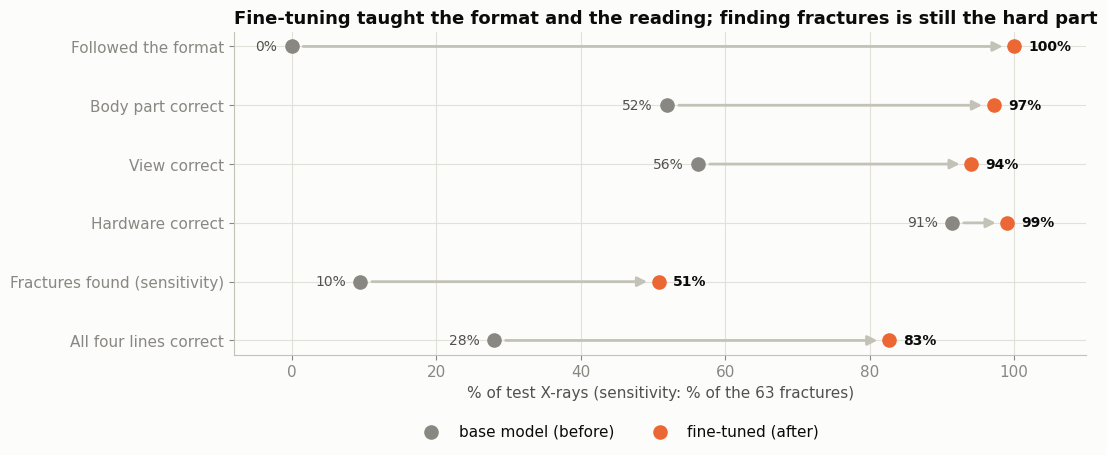

In [2]:
#@title Before → after fine-tuning (421 test X-rays)
HEAD = [("format_ok", "Followed the format"), ("acc_body_part", "Body part correct"), ("acc_view", "View correct"),
        ("acc_hardware", "Hardware correct"), ("fracture_sensitivity", "Fractures found (sensitivity)"),
        ("all_fields_correct", "All four lines correct")]
before = 100 * METRICS.loc["base", [h[0] for h in HEAD]].to_numpy(float)
after = 100 * METRICS.loc["main", [h[0] for h in HEAD]].to_numpy(float)
fig, ax = plt.subplots(figsize=(11, 4.2))
y = np.arange(len(HEAD))
for yi, b0, a0 in zip(y, before, after):
    ax.annotate("", (a0 - 1.2, yi), (b0 + 1.2, yi), arrowprops=dict(arrowstyle="-|>", color=GRAY, lw=2, mutation_scale=14))
    ax.text(b0 - 2, yi, f"{b0:.0f}%", ha="right", va="center", fontsize=10, color=INK2)
    ax.text(a0 + 2, yi, f"{a0:.0f}%", ha="left", va="center", fontsize=10, color=INK, fontweight="bold")
ax.scatter(before, y, s=90, color=GRAY_DARK, zorder=3, label="base model (before)")
ax.scatter(after, y, s=90, color=ORANGE, zorder=3, label="fine-tuned (after)")
ax.set_yticks(y, [h[1] for h in HEAD])
ax.invert_yaxis()
ax.set(xlim=(-8, 110), xlabel="% of test X-rays (sensitivity: % of the 63 fractures)")
ax.set_title("Fine-tuning taught the format and the reading; finding fractures is still the hard part")
ax.legend(loc="upper center", bbox_to_anchor=(0.45, -0.17), ncol=2)
plt.show()

---
## Before the code · A clinical view

### Would you sign this report?

We gave our fine-tuned model **a plain gray image with nothing in it**. It answered:

```
Body part: hand
View: frontal
Hardware: no
Fracture: no
```

Pure noise gets the same report. Before fine-tuning, the model just copied the answer options (`hand, leg, hip, shoulder · frontal · no · no`). You will reproduce both in Part 9. **Fluent is not the same as correct.**

### Where VLMs are being tried
- Drafting a report from the images (the most studied use)
- Answering questions about an image (visual question answering)
- Filling in structured fields and classifying findings (**this lab**)
- Triage: deciding which studies to read first

**Today they are assistants. The radiologist reviews and signs.** Clinical use needs local validation and a regulatory path; check the current FDA and EU rules before any deployment.

### When to fine-tune
Try these in order and stop at the first one that works:
1. **Prompt.** Always the baseline: free and fast. In this lab the untrained model never followed the report format and named the body part correctly only 52% of the time.
2. **Retrieve (RAG, retrieval-augmented generation)** when what is missing is text knowledge: guidelines, your protocols, prior reports.
3. **Fine-tune** when you need a new behavior or a fixed output format, a local visual skill (your scanners, your patients), a smaller model that runs on your own servers, or your department's house style.

Our task needs a fixed format and a visual skill, so we fine-tune.

### Data and labels decide the outcome
- **The label is the curriculum.** The model learns your labels, including their mistakes.
- **Readers disagree.** Label noise limits what any model can learn.
- **Shortcuts.** In FracAtlas, hardware and fractures often appear together. Our model learned to call jewelry "hardware" and then also "fracture" (Part 10).
- **Leakage.** 68 validation images are exact copies of training images under other file names; the test set has none (Part 4). Split by patient.
- **Subgroups.** Check by body part, scanner, site and age. FracAtlas comes from three hospitals in one country.
- **Governance.** An adapter trained on patient data can memorize it. Treat the weights as protected data.

### How a report goes wrong

| Error | Example | How we catch it |
|---|---|---|
| Hallucinated finding | reports a fracture that is not there | false alarms; the blank-image probe |
| Missed finding | "Fracture: no" on a fractured bone | sensitivity |
| Wrong side | left instead of right | exact match on laterality |
| Flipped negation | "no fracture" becomes "fracture" | clinical metrics, a radiologist's review |
| Wrong severity | nondisplaced called displaced | a radiologist's review |

### Pick the metric for the task
A model that always answers "no fracture" is **85% accurate** on our test set, because only 63 of the 421 test X-rays show a fracture.
- **Yes/no questions:** sensitivity, specificity and AUC (Part 7).
- **Short answers** (body part, view): exact match.
- **Free-text reports:** word-overlap scores (BLEU, ROUGE) miss clinical errors: "no acute fracture" and "acute fracture" share almost every word. Use clinical metrics that check the findings themselves (for example GREEN or RadGraph F1), plus a radiologist's review.

### Would I trust this? A checklist
1. Was it tested on images it never saw, from patients not in training?
2. Is it right on the cases that matter (the dangerous miss), not just on average?
3. Does it work on our scanners, our patients, our subgroups?
4. What does it do with an image it should refuse (blank, wrong body part, not an X-ray)?
5. Can I see why it answered (a probability, a heat map), and would I notice when it is wrong?

We come back to this list in Part 10.

---
## Part 1 · What is a vision-language model?

A VLM is a language model that has been given eyes. It has three parts:

- **Vision encoder.** A vision transformer (ViT) that turns the image into a grid of feature vectors.
- **Projector.** A small network that translates those features into "words" (tokens) the language model can read.
- **Language model.** It reads the image tokens and your question together, then writes the answer one token at a time.

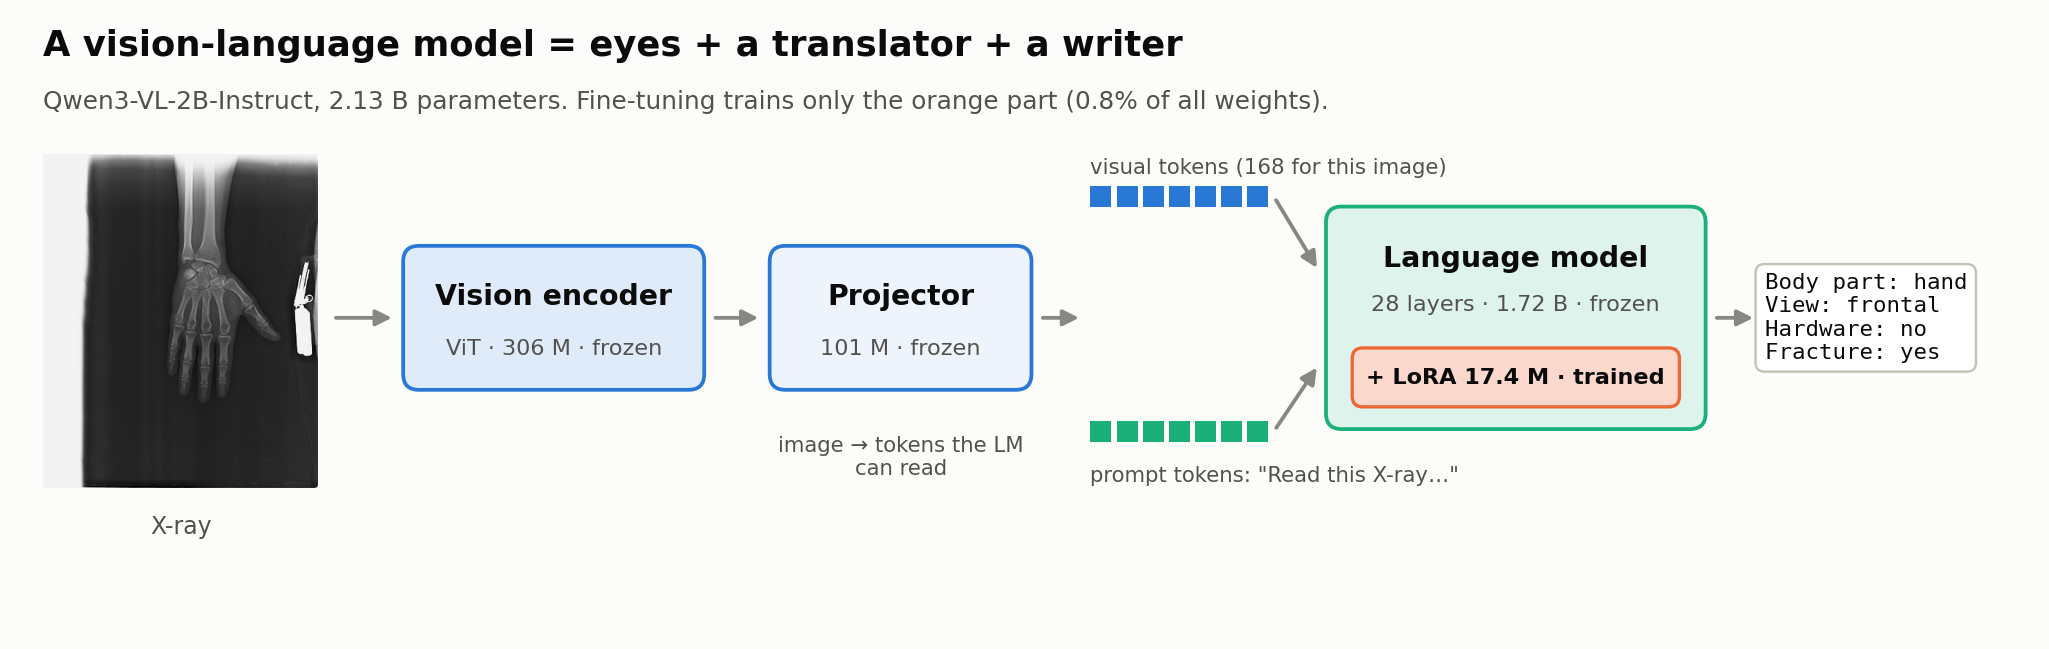

The image is cut into 16 × 16-pixel patches. Every 2 × 2 block of patches becomes one token. So **one visual token covers 32 × 32 pixels**.

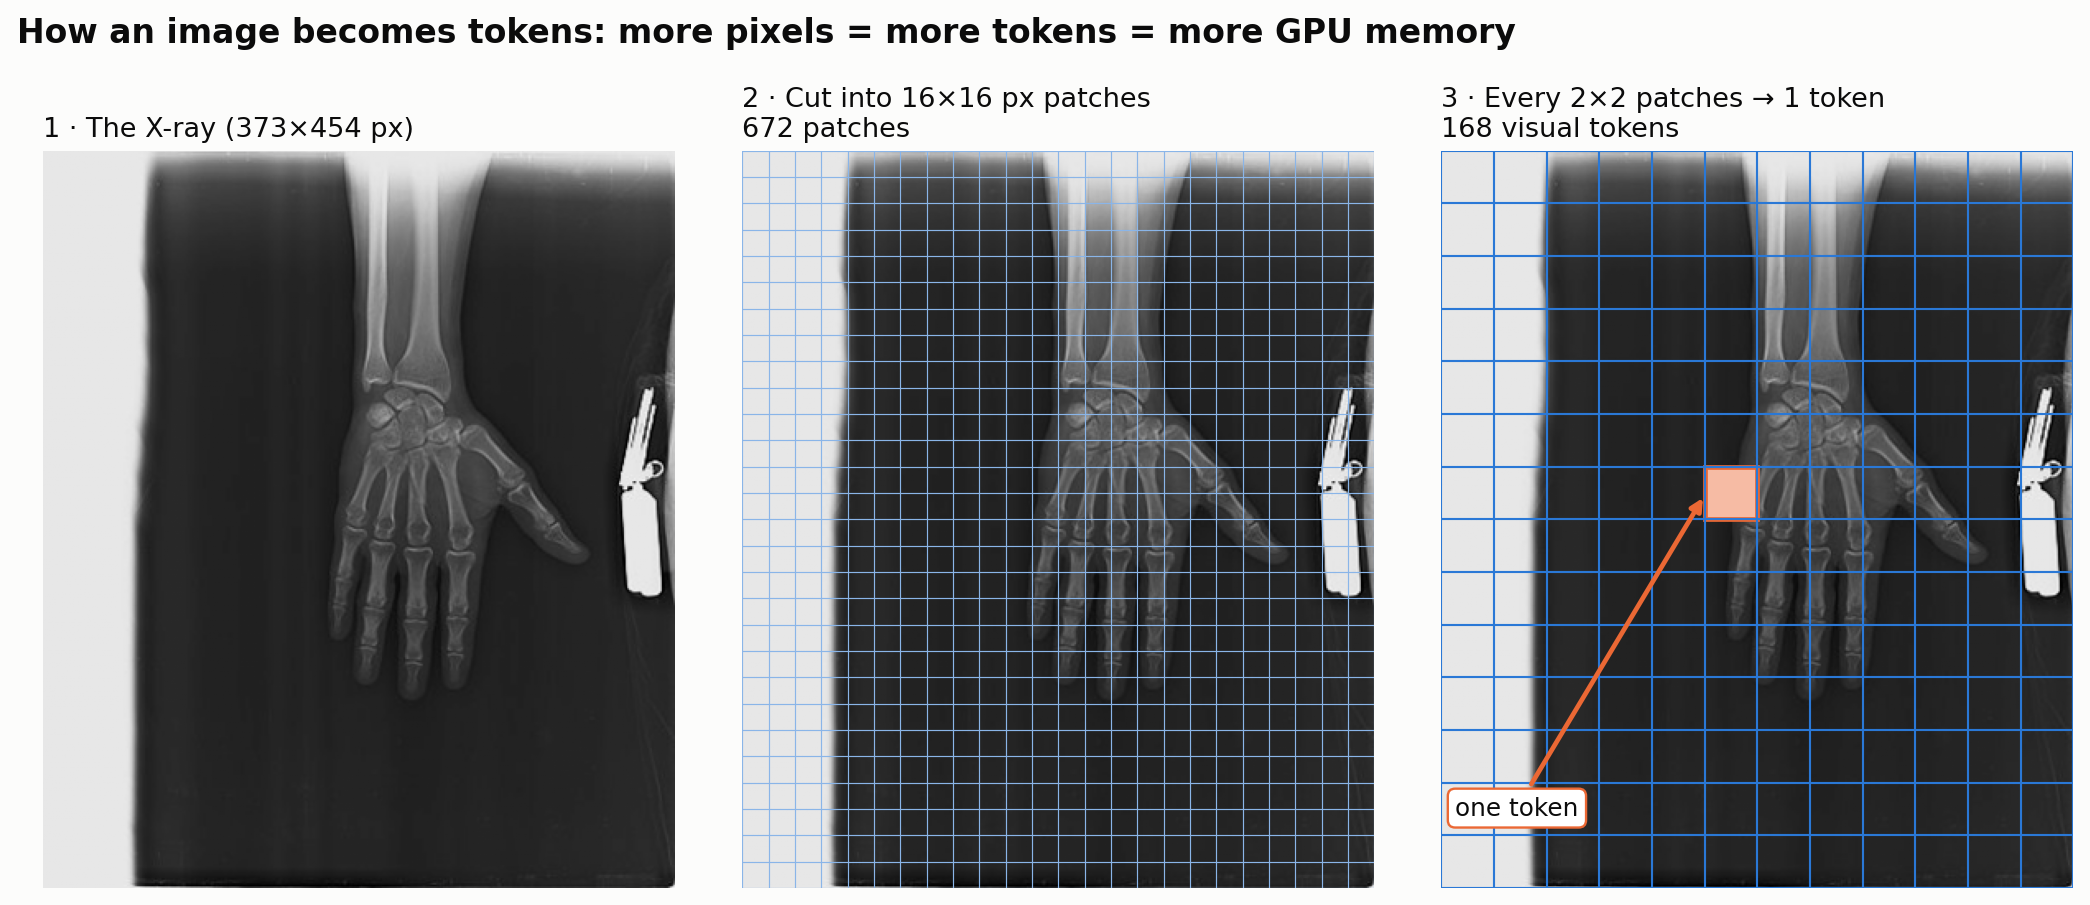

This X-ray is 373 × 454 px → 168 visual tokens (by the formula)
The real processor agrees: 28 × 24 patches → 168 tokens


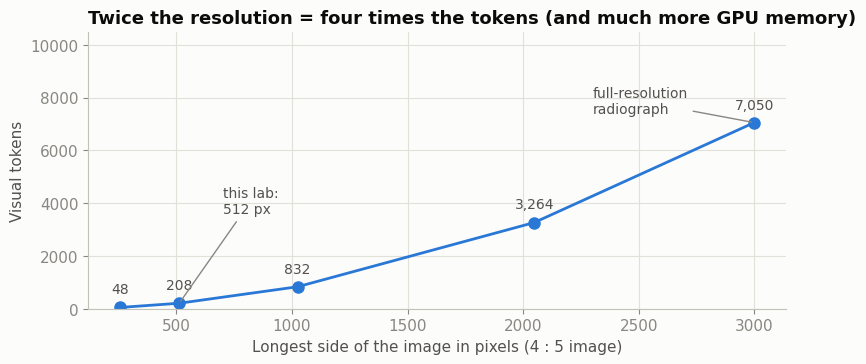

In [3]:
#@title How many tokens is an X-ray?
def visual_tokens(width, height, px_per_token=32):
    """Qwen3-VL: 16x16 px patches, merged 2x2 -> 1 token per 32x32 px (image resized to multiples of 32)."""
    return max(1, round(width / px_per_token)) * max(1, round(height / px_per_token))

iid = "IMG0003310.jpg"
w, h = image(iid).size
print(f"This X-ray is {w} × {h} px → {visual_tokens(w, h)} visual tokens (by the formula)")
if GPU:
    t, gh, gw = processor.image_processor(images=[image(iid)], return_tensors="pt")["image_grid_thw"][0].tolist()
    print(f"The real processor agrees: {gh} × {gw} patches → {gh * gw // 4} tokens")

sides = np.array([256, 512, 1024, 2048, 3000])
tokens = np.array([visual_tokens(0.8 * s, s) for s in sides])
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(sides, tokens, color=BLUE, lw=2, marker="o", ms=8)
for s, n in zip(sides, tokens):
    ax.annotate(f"{n:,}", (s, n), textcoords="offset points", xytext=(0, 10), ha="center", fontsize=10, color=INK2)
ax.annotate("this lab:\n512 px", (512, tokens[1]), xytext=(700, 3600), fontsize=10, color=INK2,
            arrowprops=dict(arrowstyle="-", color=GRAY_DARK))
ax.annotate("full-resolution\nradiograph", (3000, tokens[-1]), xytext=(2300, 7400), fontsize=10, color=INK2,
            arrowprops=dict(arrowstyle="-", color=GRAY_DARK))
ax.set(xlabel="Longest side of the image in pixels (4 : 5 image)", ylabel="Visual tokens", ylim=(0, 10500),
       title="Twice the resolution = four times the tokens (and much more GPU memory)")
plt.show()

**Why it matters.** A full-resolution radiograph would cost thousands of tokens. Memory and time grow with every token, so we resize to 512 px. That is enough for body part and view, but it can hide a subtle fracture line. **Resolution is a clinical trade-off, not just a technical one.**

---
## Part 2 · Fine-tuning strategies

Pre-training taught the model general vision and language. Fine-tuning adapts it to *our* task and *our* format. Four common strategies:

| Strategy | What is trained | Trainable weights (this model) | Fits a free T4? | Use it when |
|---|---|---|---|---|
| Prompting (no training) | nothing | 0 | ✓ | the base model already does the task |
| Prompt tuning | a few "virtual tokens" in front of the prompt | ~0.01–0.1 M | ✓ | light format nudges; weaker on images |
| **LoRA** (this lab) | small add-on matrices in the language model | **17.4 M (0.8%)** | ✓ | most adaptation tasks with hundreds to thousands of examples |
| QLoRA | LoRA on a 4-bit compressed base | 17.4 M | ✓ (less memory) | bigger models on small GPUs |
| Full fine-tuning | every weight | 2,128 M (100%) | ✗ | large datasets and a large compute budget |

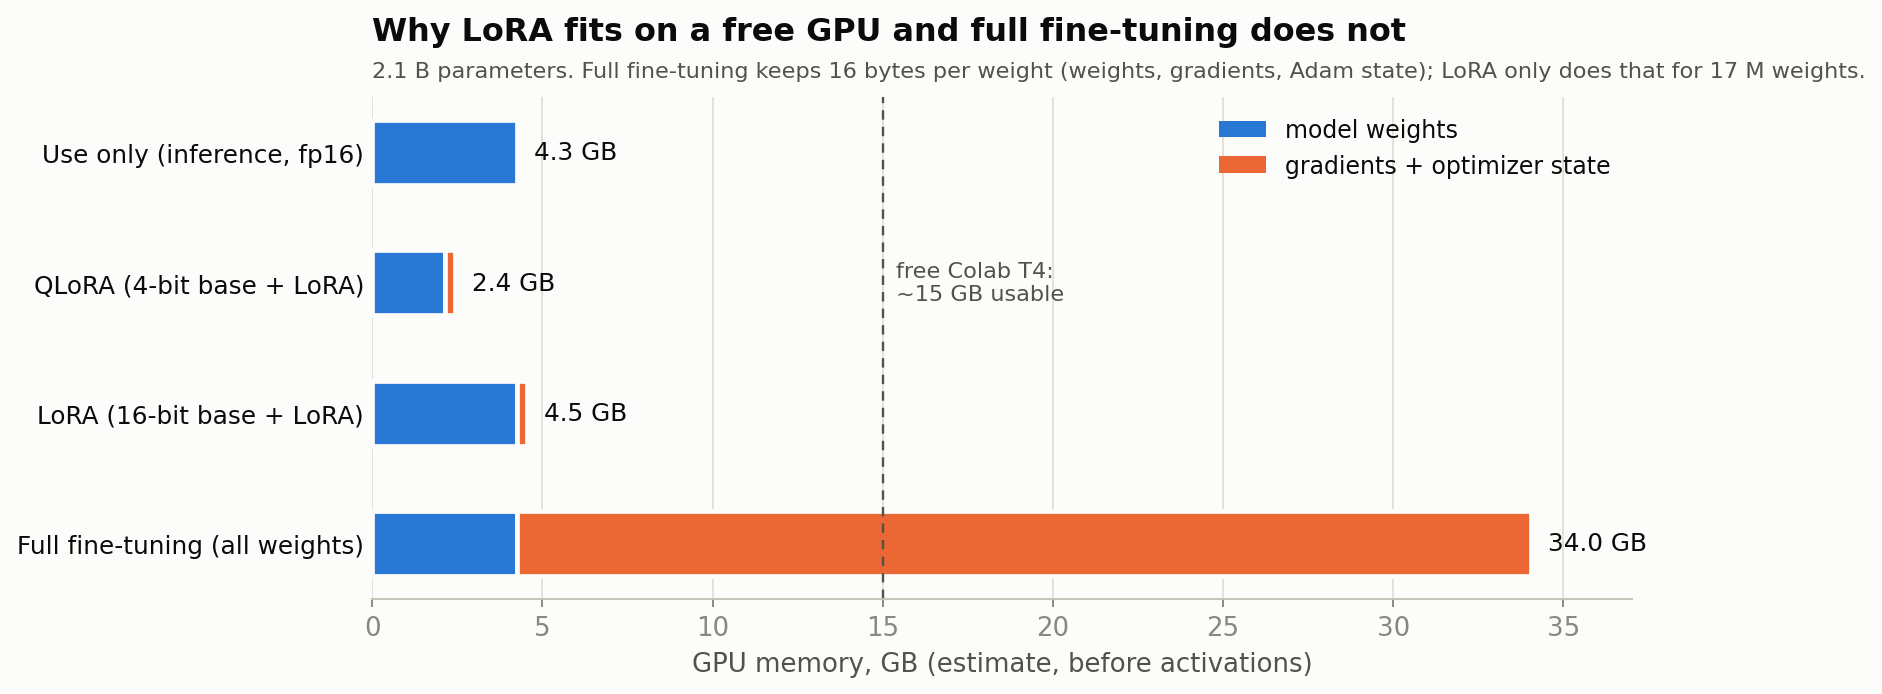

**How LoRA works.** The original weight matrix *W* stays frozen. Next to it we learn a correction *B·A* built from two thin matrices. Only *A* and *B* are trained. Afterwards they can be merged into *W* or kept as a ~70 MB file (an *adapter*) that you switch on and off.

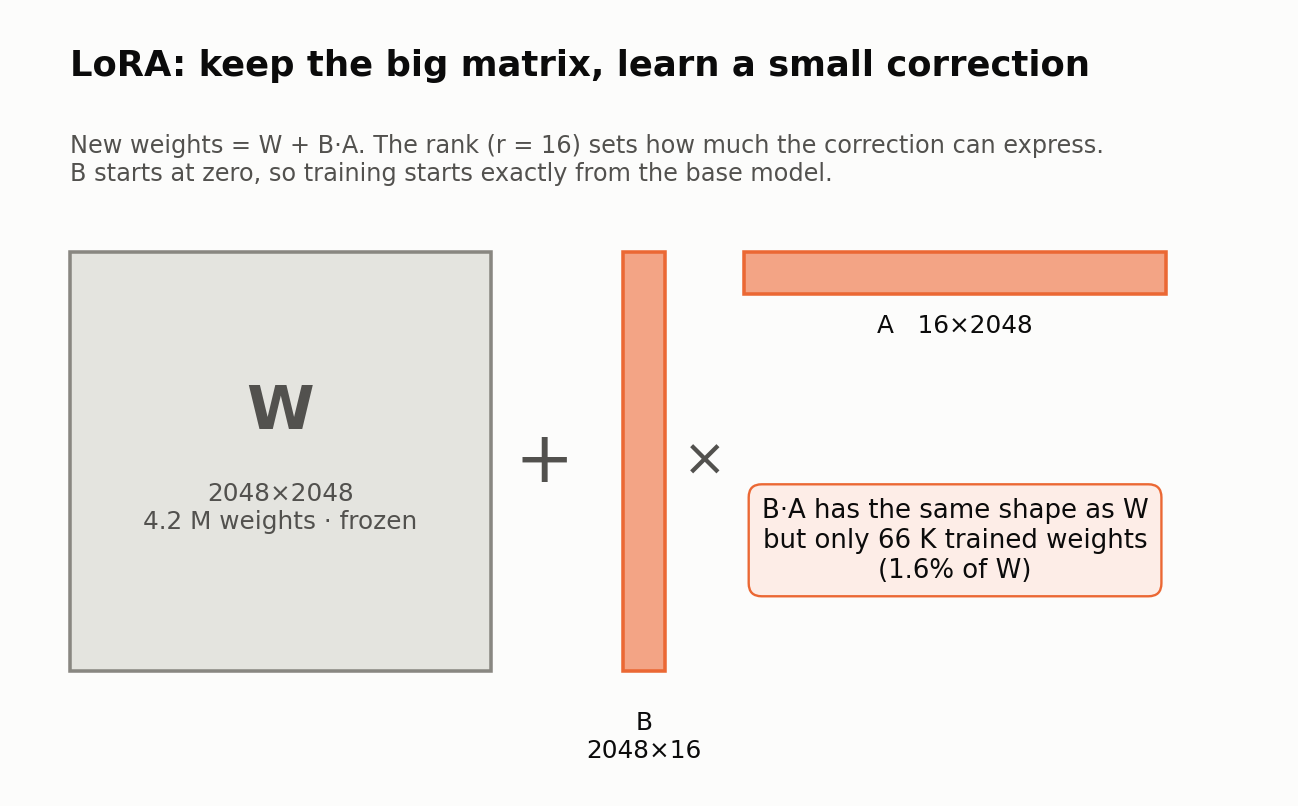

**What the model is graded on.** During training the model sees the image, the instruction and the correct report. The loss (the error signal) is computed **only on the report tokens**. We teach the answer, not how to repeat the question.

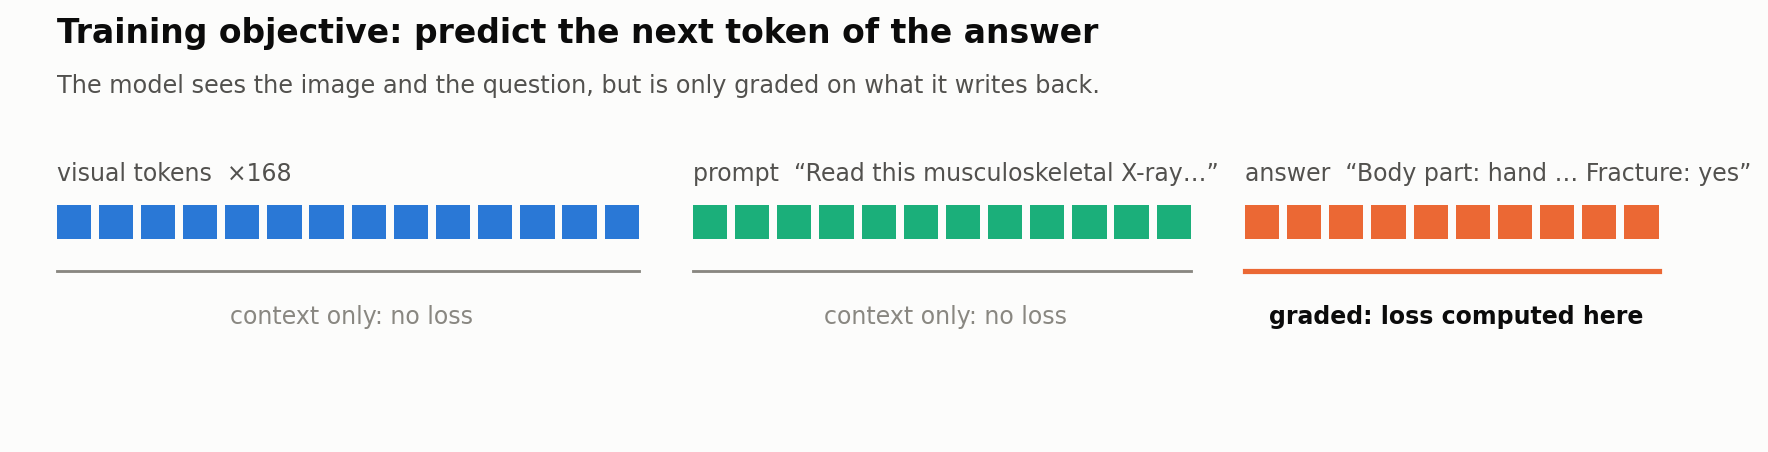

---
## Part 3 · Inspect the model

We use **Qwen3-VL-2B-Instruct**: an open-weight model with 2.1 B weights, small enough for a free GPU. Where are those weights, and which ones does our fine-tune touch?

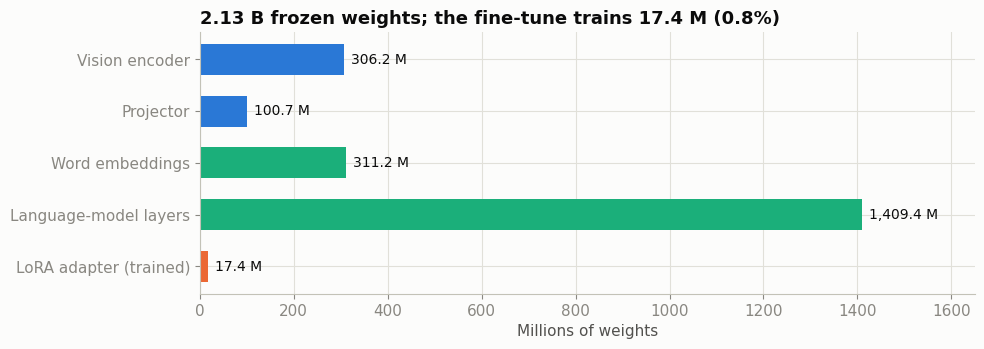

In [4]:
#@title Where are the 2.1 billion weights?
parts = {"Vision encoder": 306_242_560, "Projector": 100_714_496,
         "Word embeddings": 311_164_928, "Language-model layers": 1_409_410_048}
lora = 17_432_576
if GPU:  # count them live
    parts = dict.fromkeys(parts, 0)
    lora = 0
    for name, p in model.named_parameters():
        if "lora_" in name:
            lora += p.numel() if ".lab07." in name else 0
        elif "merger" in name:
            parts["Projector"] += p.numel()
        elif ".visual." in name:
            parts["Vision encoder"] += p.numel()
        elif "embed_tokens" in name:
            parts["Word embeddings"] += p.numel()
        else:
            parts["Language-model layers"] += p.numel()

labels = list(parts) + ["LoRA adapter (trained)"]
values = np.array(list(parts.values()) + [lora]) / 1e6
colors = [BLUE, BLUE, AQUA, AQUA, ORANGE]
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.barh(labels, values, color=colors, height=0.6)
for y, v in enumerate(values):
    ax.text(v + 15, y, f"{v:,.1f} M", va="center", fontsize=10, color=INK)
ax.invert_yaxis()
ax.set(xlabel="Millions of weights", xlim=(0, 1650))
total = sum(parts.values())
ax.set_title(f"{total / 1e9:.2f} B frozen weights; the fine-tune trains {lora / 1e6:.1f} M ({100 * lora / total:.1f}%)")
plt.show()

---
## Part 4 · The data

**FracAtlas** (Abedeen et al., *Scientific Data* 2023, CC BY 4.0) contains 4,083 musculoskeletal radiographs from three hospitals in Bangladesh. Each image is labelled for body part, view, orthopedic hardware and fracture. Fractures also have expert bounding boxes.

We resized every image to at most 512 px and split them **by image ID range**, following the authors' own split. FracAtlas has no patient IDs, and neighbouring IDs often come from the same patient, so a random split would leak patients between training and testing.

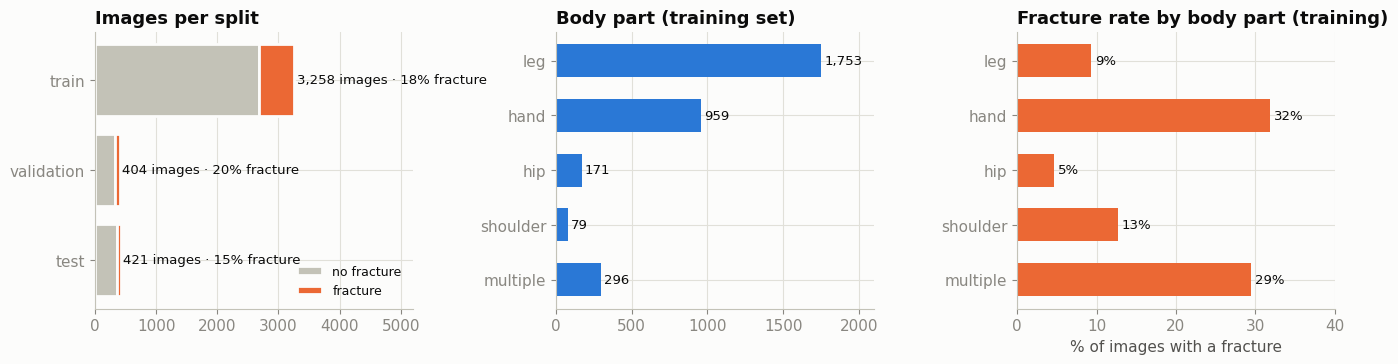

Hardware is rare: 2.4% of all images (4 test images).


In [5]:
#@title The dataset in numbers
L = LABELS.assign(body=lambda d: d.body_part.where(~d.body_part.str.contains(","), "multiple"))
splits = ["train", "validation", "test"]
fig, axes = plt.subplots(1, 3, figsize=(16, 3.6), gridspec_kw={"wspace": 0.45})

g = L.groupby("split").fracture.agg(["size", "sum"]).loc[splits]
axes[0].barh(splits, g["size"] - g["sum"], color=GRAY, edgecolor=SURFACE, lw=2, label="no fracture")
axes[0].barh(splits, g["sum"], left=g["size"] - g["sum"], color=ORANGE, edgecolor=SURFACE, lw=2, label="fracture")
for y, (n, f) in enumerate(zip(g["size"], g["sum"])):
    axes[0].text(n + 40, y, f"{n:,} images · {100 * f / n:.0f}% fracture", va="center", fontsize=9.5)
axes[0].set(title="Images per split", xlim=(0, 5200))
axes[0].legend(loc="lower right", fontsize=9)
axes[0].invert_yaxis()

order = ["leg", "hand", "hip", "shoulder", "multiple"]
tr = L[L.split == "train"]
counts = tr.body.value_counts().reindex(order, fill_value=0)
axes[1].barh(order, counts, color=BLUE, height=0.6)
for y, n in enumerate(counts):
    axes[1].text(n + 20, y, f"{n:,}", va="center", fontsize=9.5)
axes[1].set(title="Body part (training set)", xlim=(0, 2100))
axes[1].invert_yaxis()

prev = tr.groupby("body").fracture.mean().reindex(order) * 100
axes[2].barh(order, prev, color=ORANGE, height=0.6)
for y, v in enumerate(prev):
    axes[2].text(v + 0.5, y, f"{v:.0f}%", va="center", fontsize=9.5)
axes[2].set(title="Fracture rate by body part (training)", xlim=(0, 40), xlabel="% of images with a fracture")
axes[2].invert_yaxis()
plt.show()

print(f"Hardware is rare: {L.hardware.mean():.1%} of all images ({int(L[L.split == 'test'].hardware.sum())} test images).")

**Notice the imbalance.** Only about 1 in 6 images shows a fracture, and hardware is very rare. A model that always says "no" will look accurate. Keep that in mind when we score the models.

Here is what the model must learn to write. Orange boxes are the experts' fracture boxes; the model never sees them.

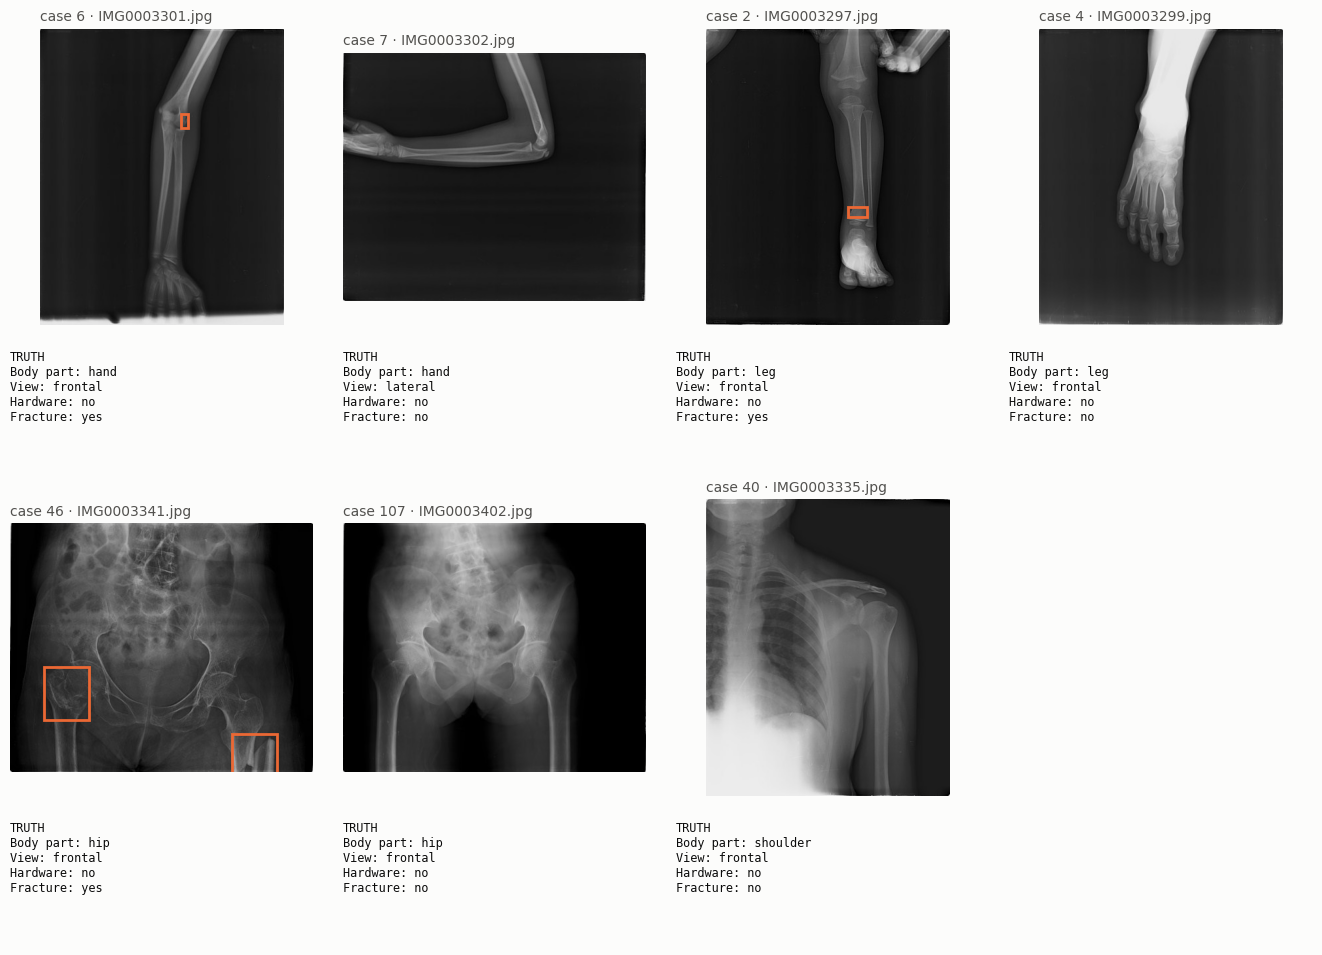

In [6]:
#@title What the model must learn to write
GALLERY = []
for bp in ["hand", "leg", "hip", "shoulder"]:
    for fx in (1, 0):
        hit = TEST[(TEST.body_part == bp) & (TEST.fracture == fx)]
        if len(hit):
            GALLERY.append(hit.index[0])
cards(GALLERY[:8], runs=())

### Are the test images really new? A duplicate check

If a test image (or a near copy) is also in the training set, the test score is inflated. File names cannot tell you this, so we compared every image by **what the vision encoder sees**. For each validation and test image we found its most similar training image (cosine similarity of image features; 1.0 = identical).

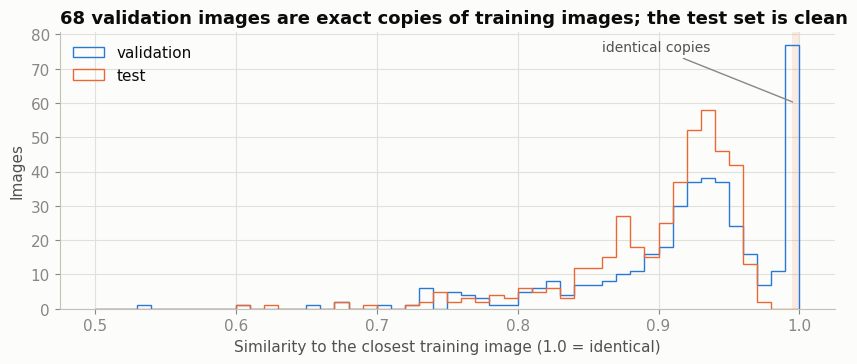

validation: 68 exact copies of a training image
test      : 0 exact copies of a training image


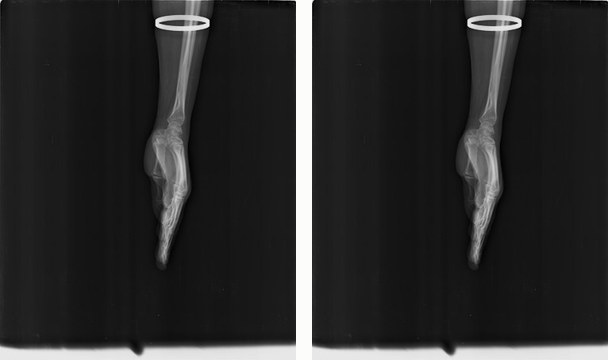

Left: training image IMG0002626 · Right: validation image IMG0004081 (same pixels, different file name)


In [7]:
#@title Nearest training image for every held-out image
nn = pd.read_csv(R / "visuals" / "nearest_train_neighbour.csv")
fig, ax = plt.subplots(figsize=(10, 3.6))
bins = np.linspace(0.5, 1.0, 51)
for split, color in [("validation", BLUE), ("test", ORANGE)]:
    ax.hist(nn[nn.split == split].cosine, bins=bins, histtype="step", lw=2, color=color, label=split)
ax.axvspan(0.995, 1.0, color=ORANGE, alpha=0.12, lw=0)
ax.annotate("identical copies", (0.997, 60), xytext=(0.86, 75), fontsize=10, color=INK2,
            arrowprops=dict(arrowstyle="-", color=GRAY_DARK))
ax.set(xlabel="Similarity to the closest training image (1.0 = identical)", ylabel="Images",
       title="68 validation images are exact copies of training images; the test set is clean")
ax.legend(loc="upper left")
plt.show()
for split in ["validation", "test"]:
    print(f"{split:10s}: {int((nn[nn.split == split].cosine > 0.999).sum())} exact copies of a training image")
display(ShowImage(filename=str(R / "visuals" / "duplicate_example.jpg"), width=520))
print("Left: training image IMG0002626 · Right: validation image IMG0004081 (same pixels, different file name)")

**Lesson.** Even a curated, published dataset can contain duplicates. Here they only affect the validation curve (which we use for monitoring). The test set we report on has no copies. **Always check before you trust a score.**

### What does the frozen vision encoder "see"?

Each dot is one X-ray, placed so that images with similar features sit close together (a t-SNE map of the image features).

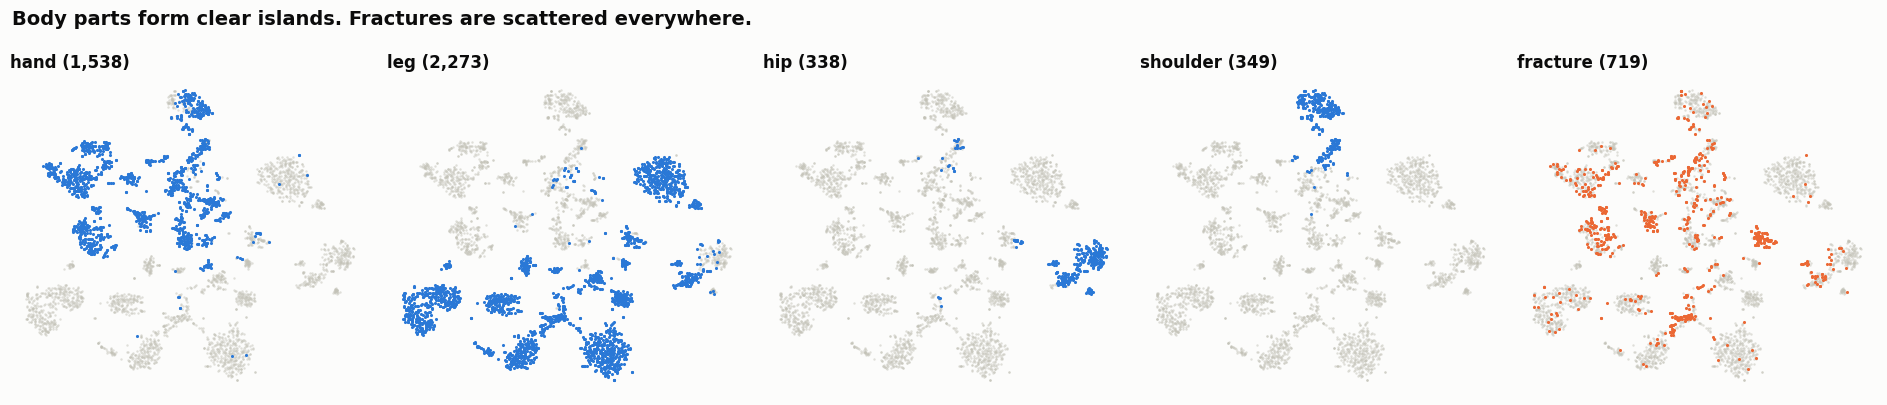

In [8]:
#@title A map of all 4,083 X-rays as the vision encoder sees them
emb = pd.read_csv(R / "visuals" / "embedding_map.csv")
fig, axes = plt.subplots(1, 5, figsize=(19, 4.1))
panels = [(bp, emb.body_part.str.contains(bp), BLUE) for bp in BODY_PARTS] + [("fracture", emb.fracture == 1, ORANGE)]
for ax, (name, hit, color) in zip(axes, panels):
    ax.scatter(emb.x[~hit], emb.y[~hit], s=3, color=GRAY, alpha=0.5, lw=0)
    ax.scatter(emb.x[hit], emb.y[hit], s=5, color=color, lw=0)
    ax.set_title(f"{name} ({hit.sum():,})", fontsize=12)
    ax.set_axis_off()
fig.suptitle("Body parts form clear islands. Fractures are scattered everywhere.", x=0.01, ha="left",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

The frozen encoder already separates anatomy well, so body part should be easy to learn. A fracture is a small local finding inside an otherwise normal-looking image, so it does not stand out in a whole-image summary. **Expect fracture detection to be the hard part.**

---
## Part 5 · Zero-shot: ask the untrained model

"Zero-shot" means we ask the base model with no task-specific training, using the same instruction we will later train on. Pick any of the 421 test X-rays with the slider.

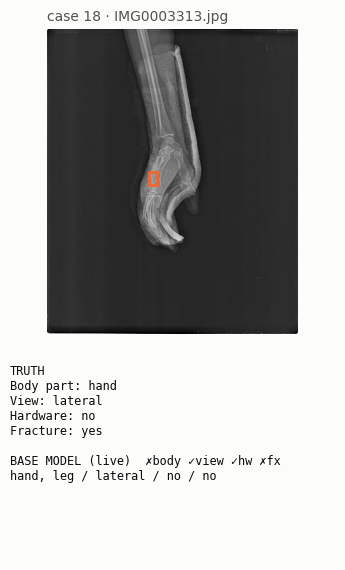

In [9]:
#@title Ask the base model about one X-ray
CASE = 18  #@param {type:"slider", min:0, max:420, step:1}
cards([TEST.index[CASE]], runs=("base",), live=GPU, ncols=1)

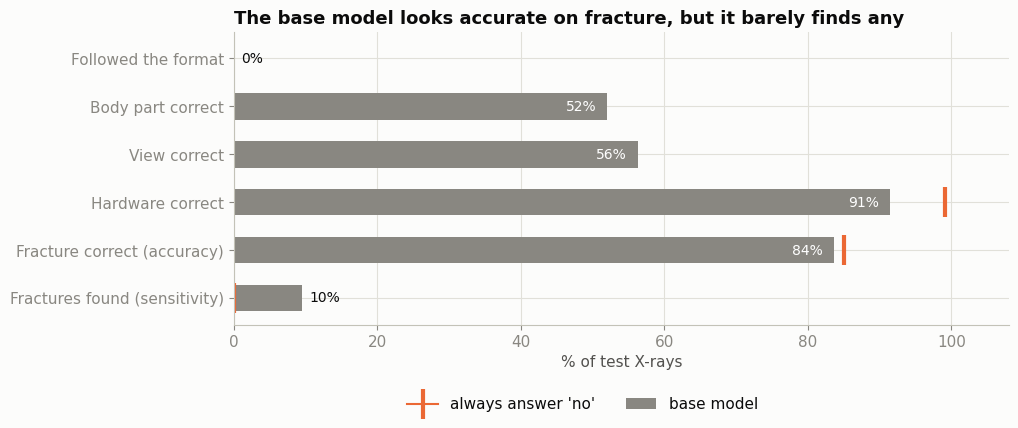

In [10]:
#@title How good is the base model on all 421 test X-rays?
b = METRICS.loc["base"]
rows = [("Followed the format", b.format_ok, None),
        ("Body part correct", b.acc_body_part, None),
        ("View correct", b.acc_view, None),
        ("Hardware correct", b.acc_hardware, 1 - TEST.hardware.mean()),
        ("Fracture correct (accuracy)", b.acc_fracture, 1 - TEST.fracture.mean()),
        ("Fractures found (sensitivity)", b.fracture_sensitivity, 0.0)]
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.barh([r[0] for r in rows], [100 * r[1] for r in rows], color=GRAY_DARK, height=0.55, label="base model")
for y, (_, v, naive) in enumerate(rows):
    inside = v > 0.2
    ax.text(100 * v - 1.5 if inside else 100 * v + 1, y, f"{100 * v:.0f}%", va="center", fontsize=10,
            ha="right" if inside else "left", color="white" if inside else INK)
    if naive is not None:
        ax.plot(100 * naive, y, marker="|", ms=22, mew=3, color=ORANGE, label="always answer 'no'" if y == 3 else None)
ax.invert_yaxis()
ax.set(xlim=(0, 108), xlabel="% of test X-rays")
ax.set_title("The base model looks accurate on fracture, but it barely finds any")
ax.legend(loc="upper center", bbox_to_anchor=(0.45, -0.2), ncol=2)
plt.show()

**The accuracy trap.** The base model is "84% accurate" on fracture, yet always answering *no* scores 85%. What matters clinically is **sensitivity** (fractures found) and **specificity** (normals correctly called normal), and the base model finds only about 1 fracture in 10. It also ignores the requested format: it writes four bare lines and often lists *every* body part.

---
## Part 6 · Fine-tune

A training example is one image, the instruction (the prompt) and the correct report (the completion). The model is graded only on the completion.

In [11]:
#@title One training example
print("PROMPT  (context: no loss is computed here)\n" + "-" * 60 + "\n[image tokens]\n" + PROMPT)
print("\nCOMPLETION  (the model is graded on these tokens)\n" + "-" * 60 + "\n" + TEST.loc[GALLERY[0], "target"])

PROMPT  (context: no loss is computed here)
------------------------------------------------------------
[image tokens]
Read this musculoskeletal X-ray and fill in the report.
Body part: hand, leg, hip or shoulder (list all that are shown)
View: frontal, lateral or oblique (list all that are shown)
Hardware: yes or no (orthopedic implant present)
Fracture: yes or no
Answer with exactly these four lines.

COMPLETION  (the model is graded on these tokens)
------------------------------------------------------------
Body part: hand
View: frontal
Hardware: no
Fracture: yes


### 🏋️ Optional: fine-tune your own adapter, live

With a GPU, this cell trains a fresh LoRA adapter on a small random sample of training X-rays: 64 images take about 1–2 minutes on a T4. This is the whole training loop: show an example, measure the error on the answer, nudge the LoRA weights, repeat. Change the settings and run it again.

Without a GPU, it shows the curve of a similar small run we did offline.

Training 17,432,576 LoRA weights on 64 X-rays for 1 epoch(s)
epoch 1/1 · image 64/64 · loss 0.023 · 13 s


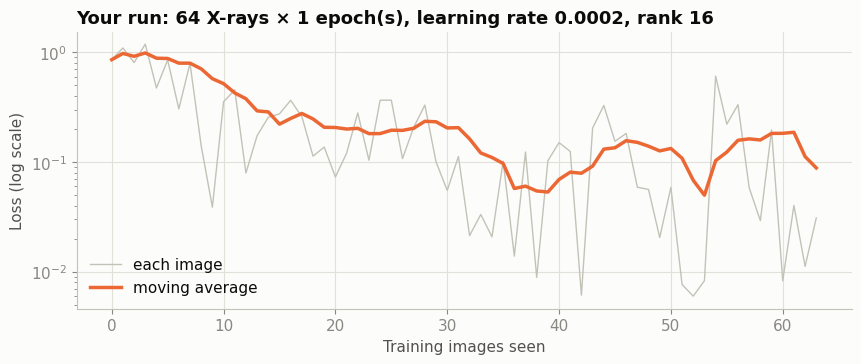

In [12]:
#@title Train (settings on the right) { display-mode: "form" }
N_IMAGES = 64  #@param {type:"slider", min:16, max:256, step:16}
EPOCHS = 1  #@param {type:"slider", min:1, max:3, step:1}
LEARNING_RATE = 2e-4  #@param [2e-5, 2e-4, 2e-3] {type:"raw"}
RANK = 16  #@param [4, 16, 64] {type:"raw"}
ACCUM = 4  # images per weight update


def encode(im, target):
    """Prompt + answer tokens. Labels are -100 on the prompt, so only the answer is graded."""
    msgs = [{"role": "user", "content": [{"type": "image", "image": im}, {"type": "text", "text": PROMPT}]}]
    prompt = processor.apply_chat_template([msgs], tokenize=True, add_generation_prompt=True,
                                           return_dict=True, return_tensors="pt")
    full = processor.apply_chat_template([msgs + [{"role": "assistant", "content": [{"type": "text", "text": target}]}]],
                                         tokenize=True, return_dict=True, return_tensors="pt")
    n = prompt["input_ids"].shape[1]
    assert torch.equal(full["input_ids"][:, :n], prompt["input_ids"]), "prompt must be a prefix of the full example"
    full["labels"] = full["input_ids"].clone()
    full["labels"][:, :n] = -100
    return full.to("cuda")


def smooth(x, k=8):
    return pd.Series(x).rolling(k, min_periods=1).mean()


if not GPU:
    tr, ev = history("fp16_n100")
    fig, ax = plt.subplots(figsize=(10, 3.6))
    ax.plot(tr.epoch, tr.loss, color=INK2, lw=2, label="training loss")
    ax.plot(ev.epoch, ev.eval_loss, color=ORANGE, lw=2, marker="o", ms=5, label="validation loss")
    ax.set(yscale="log", xlabel="Epoch (passes through the 100 images)", ylabel="Loss (log scale)",
           title="No GPU: our offline run on 100 X-rays (fp16, like a T4)")
    ax.legend()
    plt.show()
else:
    train_df = pd.read_parquet(hf_hub_download(DATA_REPO, "data/train-00000-of-00001.parquet", repo_type="dataset"))
    sample = train_df.sample(N_IMAGES, random_state=0)
    if "mine" in model.peft_config:
        model.delete_adapter("mine")
    model.add_adapter("mine", LoraConfig(r=RANK, lora_alpha=2 * RANK, lora_dropout=0.05, task_type="CAUSAL_LM",
                      target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]))
    model.set_adapter("mine")
    params = []
    for name, p in model.named_parameters():
        p.requires_grad = ".mine." in name
        if p.requires_grad:
            p.data = p.data.float()  # LoRA weights in full precision; the frozen base stays fp16
            params.append(p)
    print(f"Training {sum(p.numel() for p in params):,} LoRA weights on {N_IMAGES} X-rays for {EPOCHS} epoch(s)")
    opt = torch.optim.AdamW(params, lr=LEARNING_RATE, weight_decay=0.0)
    scaler = torch.amp.GradScaler("cuda")  # keeps small fp16 gradients from vanishing
    losses, t0 = [], time.time()
    model.train()
    for epoch in range(EPOCHS):
        rows = list(sample.sample(frac=1, random_state=epoch).itertuples())
        for i, row in enumerate(rows):
            loss = model(**encode(Image.open(io.BytesIO(row.image["bytes"])).convert("RGB"), row.target)).loss
            scaler.scale(loss / ACCUM).backward()
            losses.append(loss.item())
            if (i + 1) % ACCUM == 0 or i == len(rows) - 1:
                scaler.step(opt)
                scaler.update()
                opt.zero_grad(set_to_none=True)
            print(f"\repoch {epoch + 1}/{EPOCHS} · image {i + 1}/{len(rows)} · loss {np.mean(losses[-ACCUM:]):.3f}"
                  f" · {time.time() - t0:.0f} s", end="")
    model.eval()
    for p in params:
        p.requires_grad = False
    fig, ax = plt.subplots(figsize=(10, 3.6))
    ax.plot(losses, color=GRAY, lw=1, label="each image")
    ax.plot(smooth(losses), color=ORANGE, lw=2.5, label="moving average")
    ax.set(yscale="log", xlabel="Training images seen", ylabel="Loss (log scale)",
           title=f"Your run: {N_IMAGES} X-rays × {EPOCHS} epoch(s), learning rate {LEARNING_RATE}, rank {RANK}")
    ax.legend()
    plt.show()

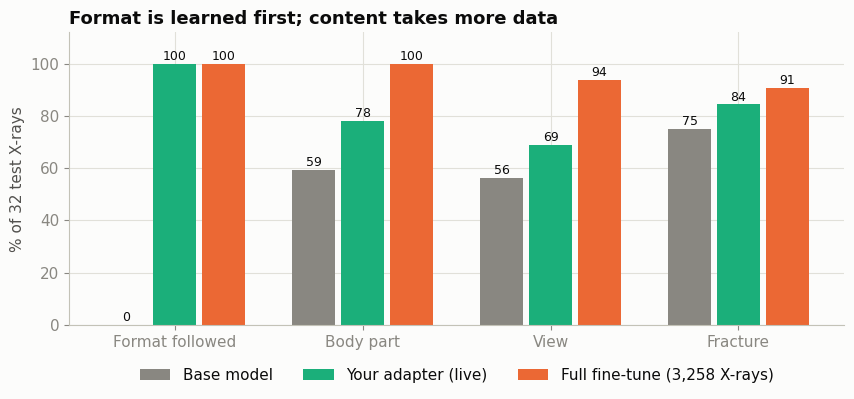

In [13]:
#@title Did it learn? Score on 32 test X-rays
EVAL_IDS = list(TEST.index[::13][:32])


def score(answers, iids):
    rows = []
    for a, iid in zip(answers, iids):
        p, t = parse_report(a), TEST.loc[iid]
        rows.append({"Format followed": p["format_ok"], "Body part": p["body_part"] == t["body_part"],
                     "View": p["view"] == t["view"], "Fracture": p["fracture"] == t["fracture"]})
    return 100 * pd.DataFrame(rows).mean()


res = {"Base model": score(preds("base").loc[EVAL_IDS, "answer"], EVAL_IDS)}
if GPU and "mine" in model.peft_config:
    mine = sum((ask([image(i) for i in EVAL_IDS[k:k + 8]], adapter="mine") for k in range(0, len(EVAL_IDS), 8)), [])
    res["Your adapter (live)"] = score(mine, EVAL_IDS)
else:
    res["Small run (100 X-rays, saved)"] = score(preds("fp16_n100").loc[EVAL_IDS, "answer"], EVAL_IDS)
res["Full fine-tune (3,258 X-rays)"] = score(preds("main").loc[EVAL_IDS, "answer"], EVAL_IDS)

df = pd.DataFrame(res)
fig, ax = plt.subplots(figsize=(10, 3.8))
x, wd = np.arange(len(df)), 0.26
for k, (col, color) in enumerate(zip(df.columns, [GRAY_DARK, AQUA, ORANGE])):
    ax.bar(x + (k - 1) * wd, df[col], wd - 0.03, color=color, label=col)
    for xi, v in zip(x, df[col]):
        ax.text(xi + (k - 1) * wd, v + 1.5, f"{v:.0f}", ha="center", fontsize=9)
ax.set_xticks(x, df.index)
ax.set(ylim=(0, 112), ylabel="% of 32 test X-rays")
ax.set_title("Format is learned first; content takes more data")
ax.legend(loc="upper center", ncol=3, bbox_to_anchor=(0.5, -0.1))
plt.show()

### Our full run

We trained the same way on all 3,258 training X-rays for 2 epochs (816 steps of 8 images; 11 minutes on one A100 GPU). Training loss is measured on the images being learned; **validation loss** is measured on held-out images and tells you whether the model is generalizing.

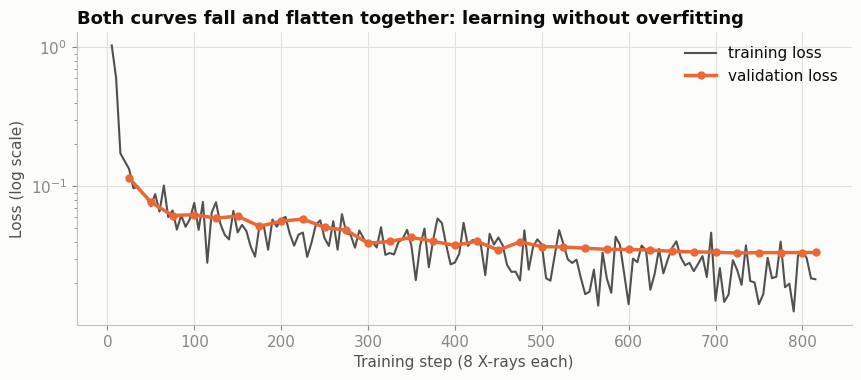

In [14]:
#@title Training and validation loss
tr, ev = history("main")
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(tr.step, tr.loss, color=INK2, lw=1.5, label="training loss")
ax.plot(ev.step, ev.eval_loss, color=ORANGE, lw=2.5, marker="o", ms=5, label="validation loss")
ax.set(yscale="log", xlabel="Training step (8 X-rays each)", ylabel="Loss (log scale)",
       title="Both curves fall and flatten together: learning without overfitting")
ax.legend()
plt.show()

---
## Part 7 · Before vs after

Now the full fine-tuned adapter against the base model, on all 421 test X-rays the model never saw.

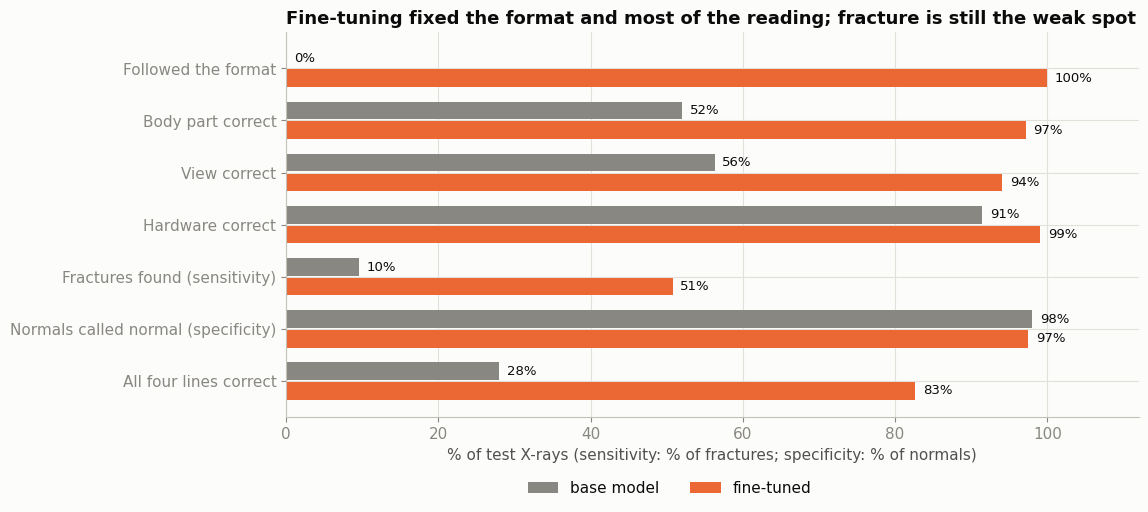

In [15]:
#@title Before vs after on 421 test X-rays
rows = [("format_ok", "Followed the format"), ("acc_body_part", "Body part correct"), ("acc_view", "View correct"),
        ("acc_hardware", "Hardware correct"), ("fracture_sensitivity", "Fractures found (sensitivity)"),
        ("fracture_specificity", "Normals called normal (specificity)"), ("all_fields_correct", "All four lines correct")]
fig, ax = plt.subplots(figsize=(11, 5))
y = np.arange(len(rows))
for k, (run, color, name) in enumerate([("base", GRAY_DARK, "base model"), ("main", ORANGE, "fine-tuned")]):
    v = 100 * METRICS.loc[run, [r[0] for r in rows]].to_numpy(float)
    ax.barh(y + (k - 0.5) * 0.38, v, 0.34, color=color, label=name)
    for yi, vi in zip(y, v):
        ax.text(vi + 1, yi + (k - 0.5) * 0.38, f"{vi:.0f}%", va="center", fontsize=9.5)
ax.set_yticks(y, [r[1] for r in rows])
ax.invert_yaxis()
ax.set(xlim=(0, 112), xlabel="% of test X-rays (sensitivity: % of fractures; specificity: % of normals)")
ax.set_title("Fine-tuning fixed the format and most of the reading; fracture is still the weak spot")
ax.legend(loc="upper center", bbox_to_anchor=(0.45, -0.13), ncol=2)
plt.show()

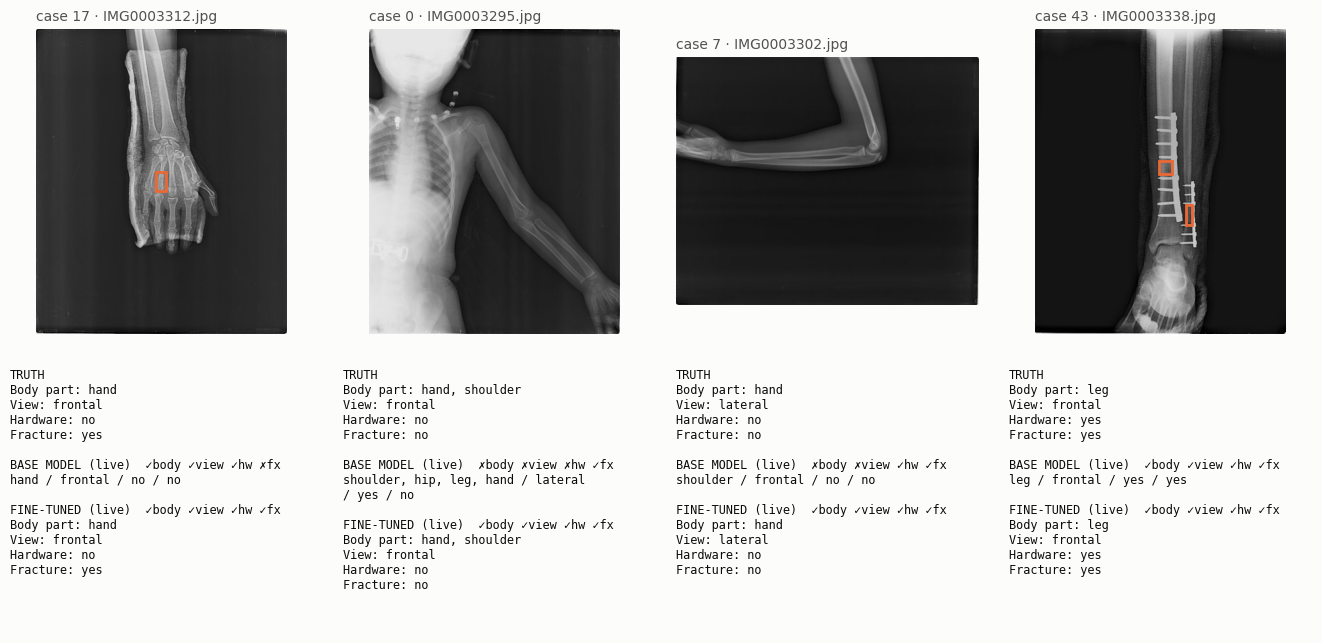

In [16]:
#@title Same X-rays, before and after
p = preds("main")
SHOW = [p[(p.true_fracture == 1) & (p.pred_fracture == 1)].index[0],
        p[p.true_body_part.str.contains(",")].index[0],
        p[(p.true_view == "lateral") & (p.true_fracture == 0)].index[0],
        p[p.true_hardware == 1].index[0]]
cards(SHOW, runs=("base", "main"), live=GPU)

### Fracture: what the yes/no answer hides

When the model writes `Fracture:`, it has a probability for "yes" and for "no". Its written answer is simply the more likely word, which is a **50% threshold**. Reading the probability directly lets us draw an ROC curve and choose a different operating point.

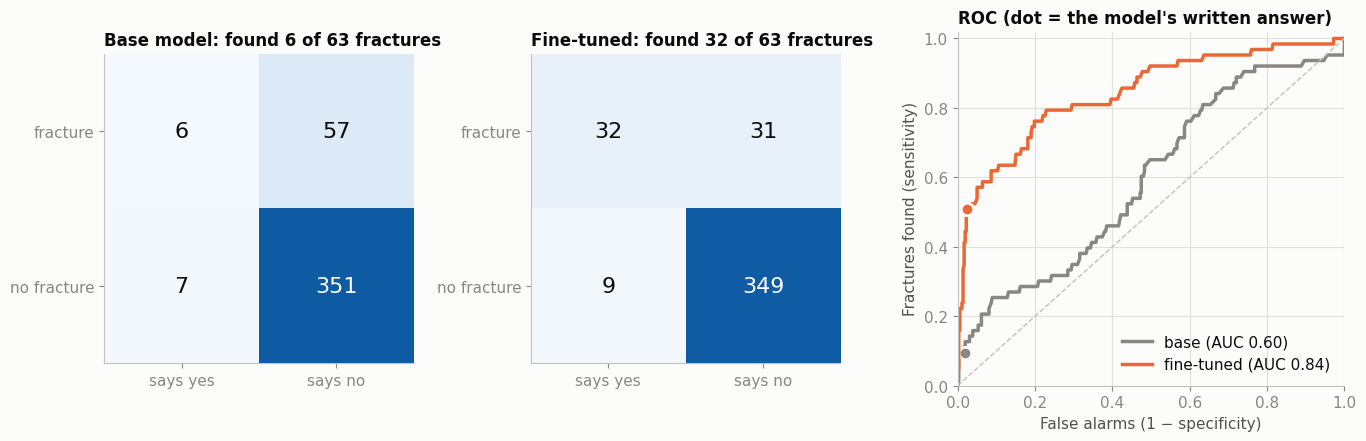

In [17]:
#@title Confusion matrices and ROC curves
from sklearn.metrics import roc_auc_score, roc_curve

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), gridspec_kw={"width_ratios": [1, 1, 1.25], "wspace": 0.35})
for ax, run, title in [(axes[0], "base", "Base model"), (axes[1], "main", "Fine-tuned")]:
    q = preds(run)
    yhat = (q.pred_fracture == 1).astype(int)
    cm = pd.crosstab(q.true_fracture, yhat).reindex(index=[1, 0], columns=[1, 0], fill_value=0).to_numpy()
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=cm.sum())
    for (i, j), n in np.ndenumerate(cm):
        ax.text(j, i, f"{n}", ha="center", va="center", fontsize=16, color="white" if n > 0.5 * cm.sum() else INK)
    ax.set_xticks([0, 1], ["says yes", "says no"])
    ax.set_yticks([0, 1], ["fracture", "no fracture"])
    ax.grid(False)
    ax.set_title(f"{title}: found {cm[0, 0]} of {cm[0].sum()} fractures", fontsize=12)

for run, color, name in [("base", GRAY_DARK, "base"), ("main", ORANGE, "fine-tuned")]:
    q = preds(run)
    fpr, tpr, _ = roc_curve(q.true_fracture, q.p_fracture)
    axes[2].plot(fpr, tpr, color=color, lw=2.5, label=f"{name} (AUC {roc_auc_score(q.true_fracture, q.p_fracture):.2f})")
    m = METRICS.loc[run]
    axes[2].plot(1 - m.fracture_specificity, m.fracture_sensitivity, "o", ms=9, color=color, mec=SURFACE, mew=2)
axes[2].plot([0, 1], [0, 1], ls="--", color=GRAY, lw=1)
axes[2].set(xlabel="False alarms (1 − specificity)", ylabel="Fractures found (sensitivity)", xlim=(0, 1), ylim=(0, 1.02))
axes[2].set_title("ROC (dot = the model's written answer)", fontsize=12)
axes[2].legend(loc="lower right")
plt.show()

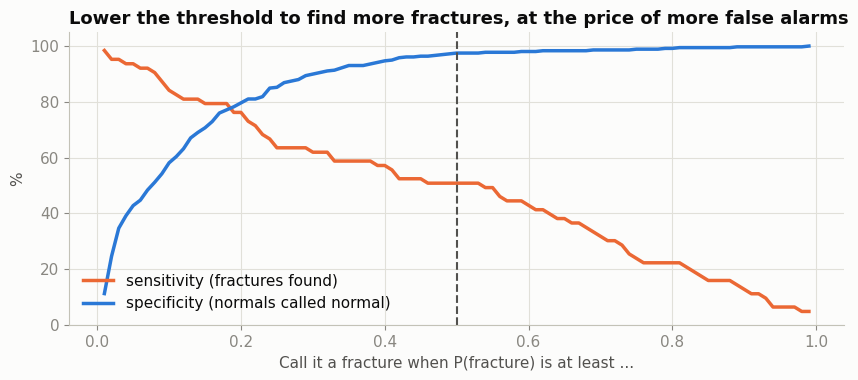

At threshold 0.50: sensitivity 51% (31 of 63 fractures missed), specificity 97% (9 false alarms in 358 normal X-rays)


In [18]:
#@title Choose your operating point
THRESHOLD = 0.5  #@param {type:"slider", min:0.02, max:0.98, step:0.02}
q = preds("main")
pos, neg = q.p_fracture[q.true_fracture == 1], q.p_fracture[q.true_fracture == 0]
thr = np.linspace(0.01, 0.99, 99)
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(thr, [100 * (pos >= t).mean() for t in thr], color=ORANGE, lw=2.5, label="sensitivity (fractures found)")
ax.plot(thr, [100 * (neg < t).mean() for t in thr], color=BLUE, lw=2.5, label="specificity (normals called normal)")
ax.axvline(THRESHOLD, color=INK2, ls="--", lw=1.5)
ax.set(xlabel="Call it a fracture when P(fracture) is at least ...", ylabel="%", ylim=(0, 105))
ax.set_title("Lower the threshold to find more fractures, at the price of more false alarms")
ax.legend(loc="lower left")
plt.show()
print(f"At threshold {THRESHOLD:.2f}: sensitivity {100 * (pos >= THRESHOLD).mean():.0f}% "
      f"({int((pos < THRESHOLD).sum())} of {len(pos)} fractures missed), specificity {100 * (neg < THRESHOLD).mean():.0f}% "
      f"({int((neg >= THRESHOLD).sum())} false alarms in {len(neg)} normal X-rays)")

**Clinical reading.** The fine-tuned model is a much better *ranker* of fractures (AUC 0.60 → 0.84), but at its plain yes/no answer (a 50% cut-off) it still misses about half of them. For triage you would lower the cut-off and accept more false alarms. That is a clinical decision, not a technical one.

---
## Part 8 · What changes the result?

We trained 10 variants offline, changing one setting at a time. All numbers are on the same 421 test X-rays.

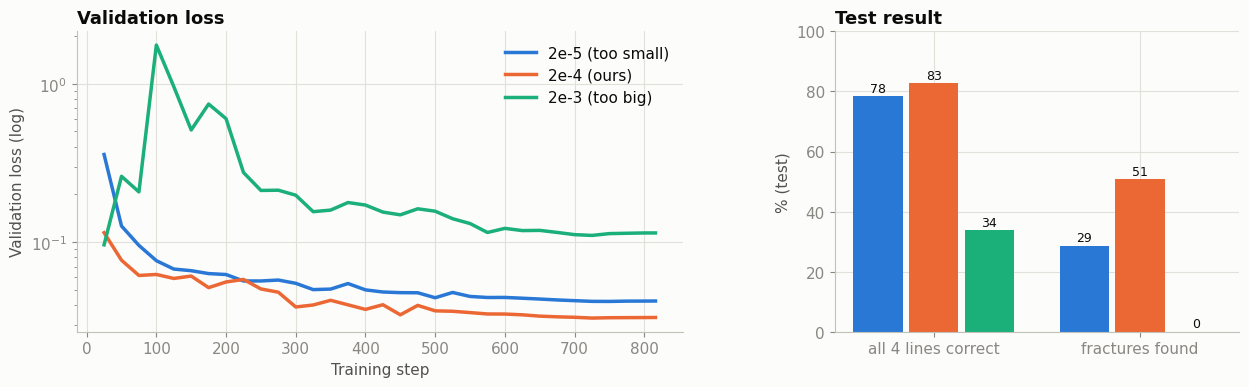

The 2e-3 adapter, run in fp16 (the T4's number format), answers:
    'Body part!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!'


In [19]:
#@title Learning rate: how big a step to take
LRS = [("lr_2e-5", "2e-5 (too small)", BLUE), ("main", "2e-4 (ours)", ORANGE), ("lr_2e-3", "2e-3 (too big)", AQUA)]
fig, axes = plt.subplots(1, 2, figsize=(15, 3.9), gridspec_kw={"width_ratios": [1.5, 1], "wspace": 0.3})
for run, name, color in LRS:
    _, ev = history(run)
    axes[0].plot(ev.step, ev.eval_loss, color=color, lw=2.5, label=name)
axes[0].set(yscale="log", xlabel="Training step", ylabel="Validation loss (log)", title="Validation loss")
axes[0].legend()
metrics = [("all_fields_correct", "all 4 lines correct"), ("fracture_sensitivity", "fractures found")]
x = np.arange(len(metrics))
for k, (run, name, color) in enumerate(LRS):
    v = 100 * METRICS.loc[run, [m[0] for m in metrics]].to_numpy(float)
    axes[1].bar(x + (k - 1) * 0.27, v, 0.24, color=color)
    for xi, vi in zip(x, v):
        axes[1].text(xi + (k - 1) * 0.27, vi + 1.5, f"{vi:.0f}", ha="center", fontsize=9)
axes[1].set_xticks(x, [m[1] for m in metrics])
axes[1].set(ylim=(0, 100), ylabel="% (test)", title="Test result")
plt.show()

print("The 2e-3 adapter, run in fp16 (the T4's number format), answers:\n   ", repr(preds("lr_2e-3_fp16").answer.iloc[0]))

- **Too small (2e-5):** learns slowly; after the same time it still misses more fractures.
- **Too big (2e-3):** validation loss jumps up early and never recovers. The model learns to always say "no fracture" (0% sensitivity).
- The 2e-3 adapter also hides a surprise. It was trained in bf16 on an A100, where it works. In **fp16**, the number format of a T4, its oversized weights overflow and it writes `Body part!!!!!!!!`. **Test the model on the hardware you will deploy it on.**

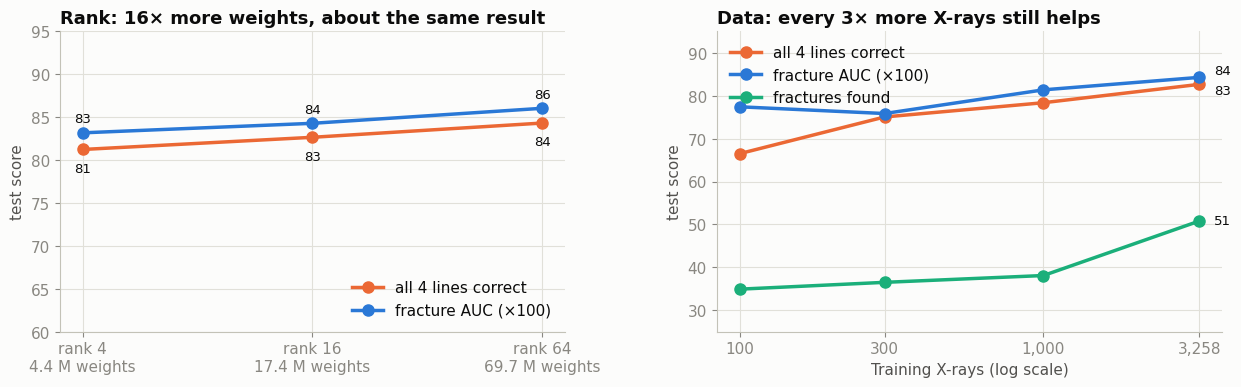

In [20]:
#@title LoRA rank and amount of data
fig, axes = plt.subplots(1, 2, figsize=(15, 3.9), gridspec_kw={"wspace": 0.3})
RANKS = [("rank_4", 4), ("main", 16), ("rank_64", 64)]
mil = [config(r)["trainable_params"] / 1e6 for r, _ in RANKS]
for k, (m, name, color) in enumerate([("all_fields_correct", "all 4 lines correct", ORANGE),
                                      ("fracture_auc", "fracture AUC (×100)", BLUE)]):
    v = [100 * METRICS.loc[r, m] for r, _ in RANKS]
    axes[0].plot(range(3), v, color=color, lw=2.5, marker="o", ms=8, label=name)
    for i, vi in enumerate(v):
        axes[0].text(i, vi + (1.2 if m == "fracture_auc" else -2.6), f"{vi:.0f}", ha="center", fontsize=9.5)
axes[0].set_xticks(range(3), [f"rank {r}\n{m:.1f} M weights" for (_, r), m in zip(RANKS, mil)])
axes[0].set(ylim=(60, 95), ylabel="test score", title="Rank: 16× more weights, about the same result")
axes[0].legend(loc="lower right")

SIZES = [("n_100", 100), ("n_300", 300), ("n_1000", 1000), ("main", 3258)]
n = [s for _, s in SIZES]
for m, name, color in [("all_fields_correct", "all 4 lines correct", ORANGE),
                       ("fracture_auc", "fracture AUC (×100)", BLUE),
                       ("fracture_sensitivity", "fractures found", AQUA)]:
    v = [100 * METRICS.loc[r, m] for r, _ in SIZES]
    axes[1].plot(n, v, color=color, lw=2.5, marker="o", ms=8, label=name)
    axes[1].text(n[-1] * 1.12, v[-1] + {"fracture_auc": 1.5, "all_fields_correct": -1.5}.get(m, 0), f"{v[-1]:.0f}",
                 va="center", fontsize=9.5)
axes[1].set(xscale="log", xlabel="Training X-rays (log scale)", ylabel="test score", ylim=(25, 95),
            title="Data: every 3× more X-rays still helps")
axes[1].set_xticks(n, [f"{s:,}" for s in n])
axes[1].minorticks_off()
axes[1].legend(loc="upper left")
plt.show()

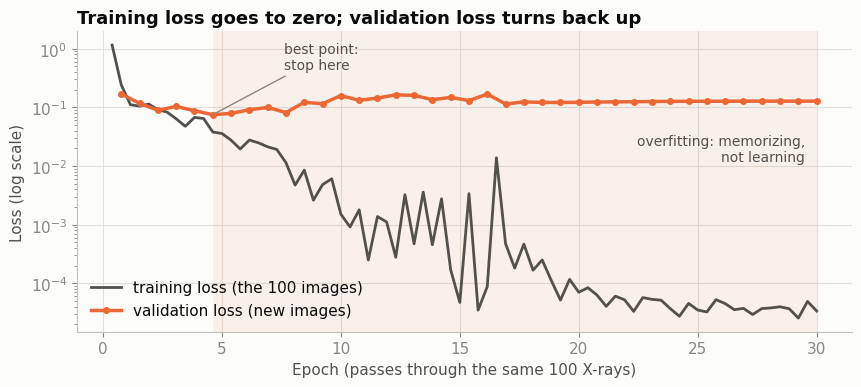

In [21]:
#@title Overfitting: 100 X-rays, 30 passes
tr, ev = history("overfit_100")
best = ev.loc[ev.eval_loss.idxmin()]
fig, ax = plt.subplots(figsize=(10, 3.9))
ax.plot(tr.epoch, tr.loss, color=INK2, lw=2, label="training loss (the 100 images)")
ax.plot(ev.epoch, ev.eval_loss, color=ORANGE, lw=2.5, marker="o", ms=4, label="validation loss (new images)")
ax.axvspan(best.epoch, ev.epoch.max(), color=ORANGE, alpha=0.08, lw=0)
ax.annotate("best point:\nstop here", (best.epoch, best.eval_loss), xytext=(best.epoch + 3, best.eval_loss * 6),
            fontsize=10, color=INK2, arrowprops=dict(arrowstyle="-", color=GRAY_DARK))
ax.text(ev.epoch.max() - 0.5, 0.012, "overfitting: memorizing,\nnot learning", ha="right", fontsize=10, color=INK2)
ax.set(yscale="log", xlabel="Epoch (passes through the same 100 X-rays)", ylabel="Loss (log scale)")
ax.set_title("Training loss goes to zero; validation loss turns back up")
ax.legend(loc="lower left")
plt.show()

### Every experiment at a glance

One row per model, one column per score, all on the same 421 test X-rays. Darker = better (everything below 50 is palest). Read down a column to see which setting mattered.

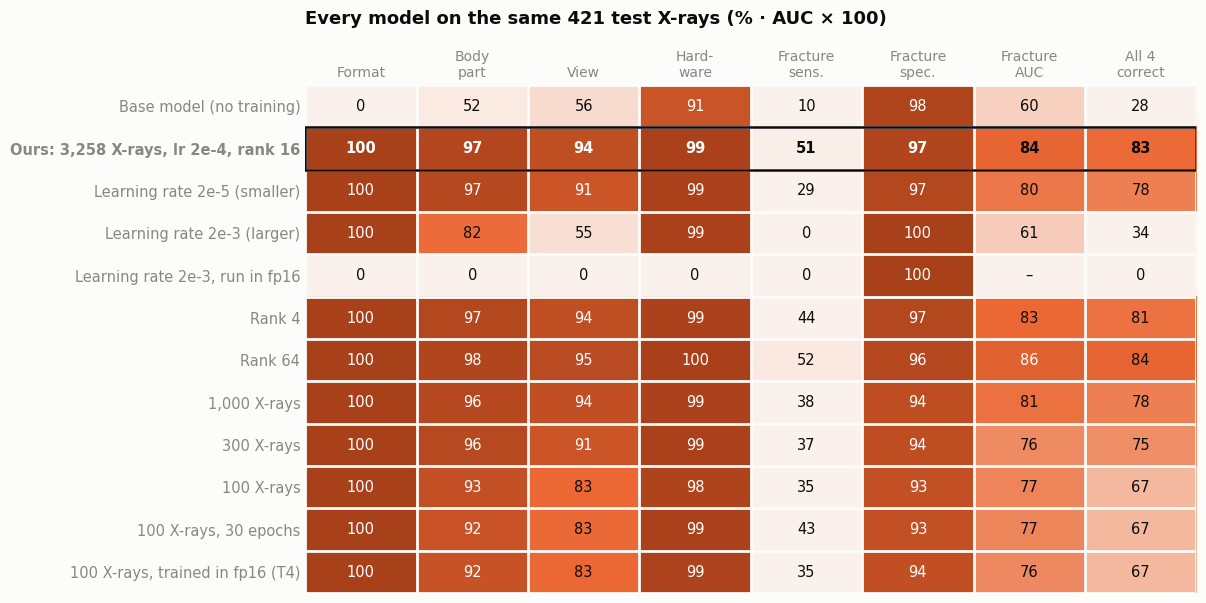

In [22]:
#@title All 12 models side by side
from matplotlib.colors import LinearSegmentedColormap
RUNS = [("base", "Base model (no training)"), ("main", "Ours: 3,258 X-rays, lr 2e-4, rank 16"),
        ("lr_2e-5", "Learning rate 2e-5 (smaller)"), ("lr_2e-3", "Learning rate 2e-3 (larger)"),
        ("lr_2e-3_fp16", "Learning rate 2e-3, run in fp16"), ("rank_4", "Rank 4"), ("rank_64", "Rank 64"),
        ("n_1000", "1,000 X-rays"), ("n_300", "300 X-rays"), ("n_100", "100 X-rays"),
        ("overfit_100", "100 X-rays, 30 epochs"), ("fp16_n100", "100 X-rays, trained in fp16 (T4)")]
COLS = [("format_ok", "Format"), ("acc_body_part", "Body\npart"), ("acc_view", "View"), ("acc_hardware", "Hard-\nware"),
        ("fracture_sensitivity", "Fracture\nsens."), ("fracture_specificity", "Fracture\nspec."),
        ("fracture_auc", "Fracture\nAUC"), ("all_fields_correct", "All 4\ncorrect")]
V = 100 * METRICS.loc[[r for r, _ in RUNS], [c for c, _ in COLS]].to_numpy(float)
cmap = LinearSegmentedColormap.from_list("seq", ["#fbf1ec", "#f4b89f", ORANGE, "#a8401a"])
fig, ax = plt.subplots(figsize=(11.5, 6.6))
ax.imshow(np.nan_to_num(V, nan=0), cmap=cmap, vmin=50, vmax=100, aspect="auto")  # below 50 = palest
for i in range(V.shape[0]):
    for j in range(V.shape[1]):
        v = V[i, j]
        ax.text(j, i, "–" if np.isnan(v) else f"{v:.0f}", ha="center", va="center", fontsize=10.5,
                color="white" if v >= 85 else INK, fontweight="bold" if RUNS[i][0] == "main" else "normal")
ax.set_xticks(range(len(COLS)), [c for _, c in COLS], fontsize=10)
ax.set_yticks(range(len(RUNS)), [r for _, r in RUNS], fontsize=10.5)
ax.tick_params(length=0, labelbottom=False, labeltop=True)
ax.get_yticklabels()[1].set_fontweight("bold")
ax.grid(False)
for sp in ax.spines.values():
    sp.set_visible(False)
ax.set_xticks(np.arange(-0.5, len(COLS)), minor=True)
ax.set_yticks(np.arange(-0.5, len(RUNS)), minor=True)
ax.grid(which="minor", color=SURFACE, linewidth=2)
ax.tick_params(which="minor", length=0)
ax.add_patch(Rectangle((-0.5, 0.5), len(COLS), 1, fill=False, edgecolor=INK, lw=1.8))
ax.set_title("Every model on the same 421 test X-rays (% · AUC × 100)", pad=44)
plt.show()

- **Format** is learned by every training run, even from 100 X-rays (the 2e-3 adapter only breaks when it runs in fp16). **Fracture** is what needs more data.
- **Learning rate** matters more than **rank**: going from rank 4 to 64 lifts fracture sensitivity from 44% to 52%, but a learning rate of 2e-3 finds no fractures at all.
- The **fp16** row is the same 2e-3 adapter, just run with a different number format: it falls to 0 everywhere.

---
## Part 9 · Failure probes

Good scores on the test set are not the whole story. We probe the model with inputs it was never meant to see.

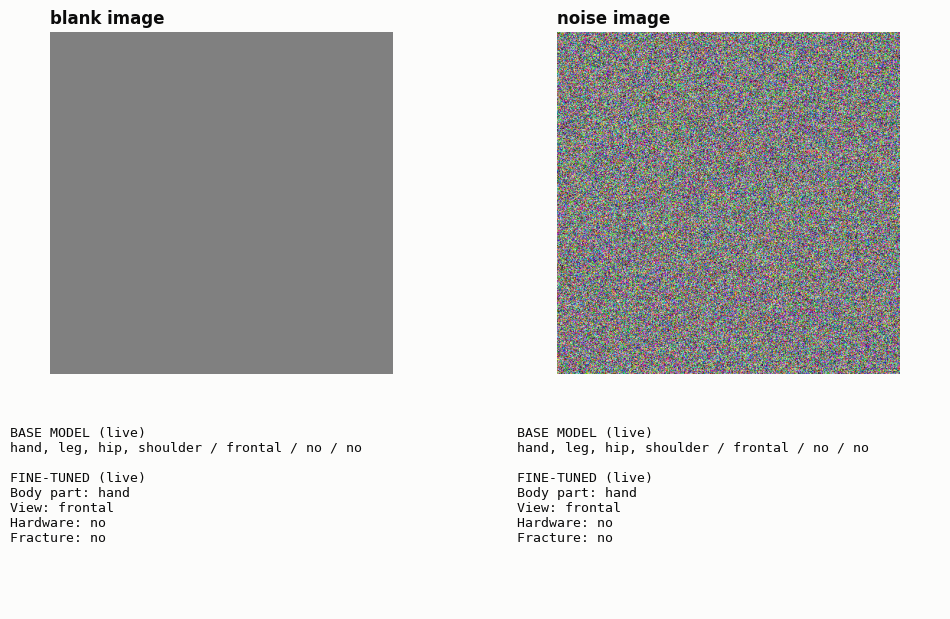

In [23]:
#@title Hallucination: a blank image and pure noise
blank = Image.new("RGB", (448, 448), (128, 128, 128))
noise = Image.fromarray(np.random.default_rng(0).integers(0, 256, (448, 448, 3), dtype=np.uint8))
probes = {(p["probe"], p["question"]): p for p in json.loads((R / "visuals" / "probes.json").read_text())}
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5), gridspec_kw={"height_ratios": [3, 1.6]})
for c, (name, im) in enumerate([("blank", blank), ("noise", noise)]):
    axes[0, c].imshow(im)
    axes[0, c].set_axis_off()
    axes[0, c].set_title(f"{name} image", fontsize=12)
    if GPU:
        base_a, ft_a, tag = ask(im, adapter=None), ask(im), " (live)"
    else:
        base_a, ft_a, tag = probes[(name, "report")]["base"], probes[(name, "report")]["finetuned"], ""
    axes[1, c].text(0, 1, f"BASE MODEL{tag}\n{' / '.join(base_a.splitlines())}\n\nFINE-TUNED{tag}\n{ft_a}",
                    va="top", family="monospace", fontsize=9.5, transform=axes[1, c].transAxes)
    axes[1, c].set_axis_off()
plt.show()

Both models write a confident report about a "hand" on an image that contains **no X-ray at all**. A VLM does not say "I don't know" unless it was trained to. Fine-tuning made the report look more professional, which makes the error **more** convincing. In practice you need input checks (is this an X-ray? the right body part?) before the model, and you should teach it to refuse.

In [24]:
#@title Forgetting and robustness: other questions, a rotated image
rows = []
for (probe, question), p in probes.items():
    if probe in ("blank", "noise"):
        continue
    q = {"report": "the report prompt", "describe": "Describe this image in one sentence.",
         "yes_no": "Is there a fracture in this X-ray? Answer yes or no."}[question]
    rows.append({"image": f"{probe} ({p['image_id']})", "question": q, "truth": TEST.loc[p["image_id"], "target"].replace("\n", " / ") if p["image_id"] in TEST.index else "",
                 "base model": p["base"].replace("\n", " / "), "fine-tuned": p["finetuned"].replace("\n", " / ")})
pd.set_option("display.max_colwidth", 200)
display(pd.DataFrame(rows).style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"}).hide(axis="index"))

image,question,truth,base model,fine-tuned
fracture (IMG0003297.jpg),the report prompt,Body part: leg / View: frontal / Hardware: no / Fracture: yes,leg / frontal / no / no,Body part: leg / View: frontal / Hardware: no / Fracture: no
fracture (IMG0003297.jpg),Describe this image in one sentence.,Body part: leg / View: frontal / Hardware: no / Fracture: yes,"This is an X-ray image of a child's lower leg and foot, showing the bones of the tibia and fibula, the ankle joint, and the foot.","This is an X-ray of a child's lower leg, showing the bones of the leg and foot, with the foot being the most prominent feature."
fracture (IMG0003297.jpg),Is there a fracture in this X-ray? Answer yes or no.,Body part: leg / View: frontal / Hardware: no / Fracture: yes,no,no
hardware (IMG0003338.jpg),the report prompt,Body part: leg / View: frontal / Hardware: yes / Fracture: yes,leg / frontal / yes / yes,Body part: leg / View: frontal / Hardware: yes / Fracture: yes
hardware (IMG0003338.jpg),Describe this image in one sentence.,Body part: leg / View: frontal / Hardware: yes / Fracture: yes,"This is an X-ray image of a lower leg and foot showing a fracture with multiple metal implants, including a bone plate and screws, indicating a recent surgical repair.","This is a radiograph of a leg showing a fracture with multiple metal plates and screws, likely from a surgical intervention."
hardware (IMG0003338.jpg),Is there a fracture in this X-ray? Answer yes or no.,Body part: leg / View: frontal / Hardware: yes / Fracture: yes,yes,yes
hip (IMG0003341.jpg),the report prompt,Body part: hip / View: frontal / Hardware: no / Fracture: yes,"hip, leg / frontal / yes / no",Body part: hip / View: frontal / Hardware: no / Fracture: no
rotated_90 (IMG0003297.jpg),the report prompt,Body part: leg / View: frontal / Hardware: no / Fracture: yes,leg / lateral / no / no,Body part: leg / View: lateral / Hardware: no / Fracture: no


- **Catastrophic forgetting?** Not here. Asked a different question ("describe this image"), the fine-tuned model still answers in normal prose. LoRA left the original weights untouched, and 2 short epochs did not overwrite the model's general skills. Longer or full fine-tuning can.
- **Robustness.** Rotating the same leg X-ray by 90° changes the *view* the model reports. The model learned shortcuts from image orientation, not true anatomy.

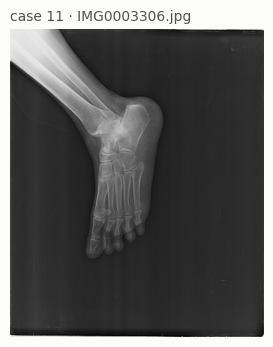

Truth: Body part: leg / View: oblique / Hardware: no / Fracture: no
Base model : no
Fine-tuned : no


In [25]:
#@title 🧪 Try your own question (GPU)
QUESTION = "Is there an orthopedic implant in this X-ray? Answer yes or no."  #@param {type:"string"}
CASE = 11  #@param {type:"slider", min:0, max:420, step:1}
iid = TEST.index[CASE]
fig, ax = plt.subplots(figsize=(4, 4))
show_xray(ax, iid, title=f"case {CASE} · {iid}")
plt.show()
print("Truth:", TEST.loc[iid, "target"].replace("\n", " / "))
if GPU:
    print("Base model :", ask(image(iid), QUESTION, adapter=None))
    print("Fine-tuned :", ask(image(iid), QUESTION))
else:
    print("(needs a GPU runtime to ask new questions)")

### Where does the model look?

**Occlusion test.** Cover one 64 × 64-pixel patch of the image with gray, ask again, and measure how much the probability of "Fracture: yes" drops. Repeat across the whole image. Patches that matter light up.

We show four fractures where the fine-tuned model is about 90% sure. When it is 99% sure, covering one patch barely moves the probability (it is *saturated*) and the map comes out blank.

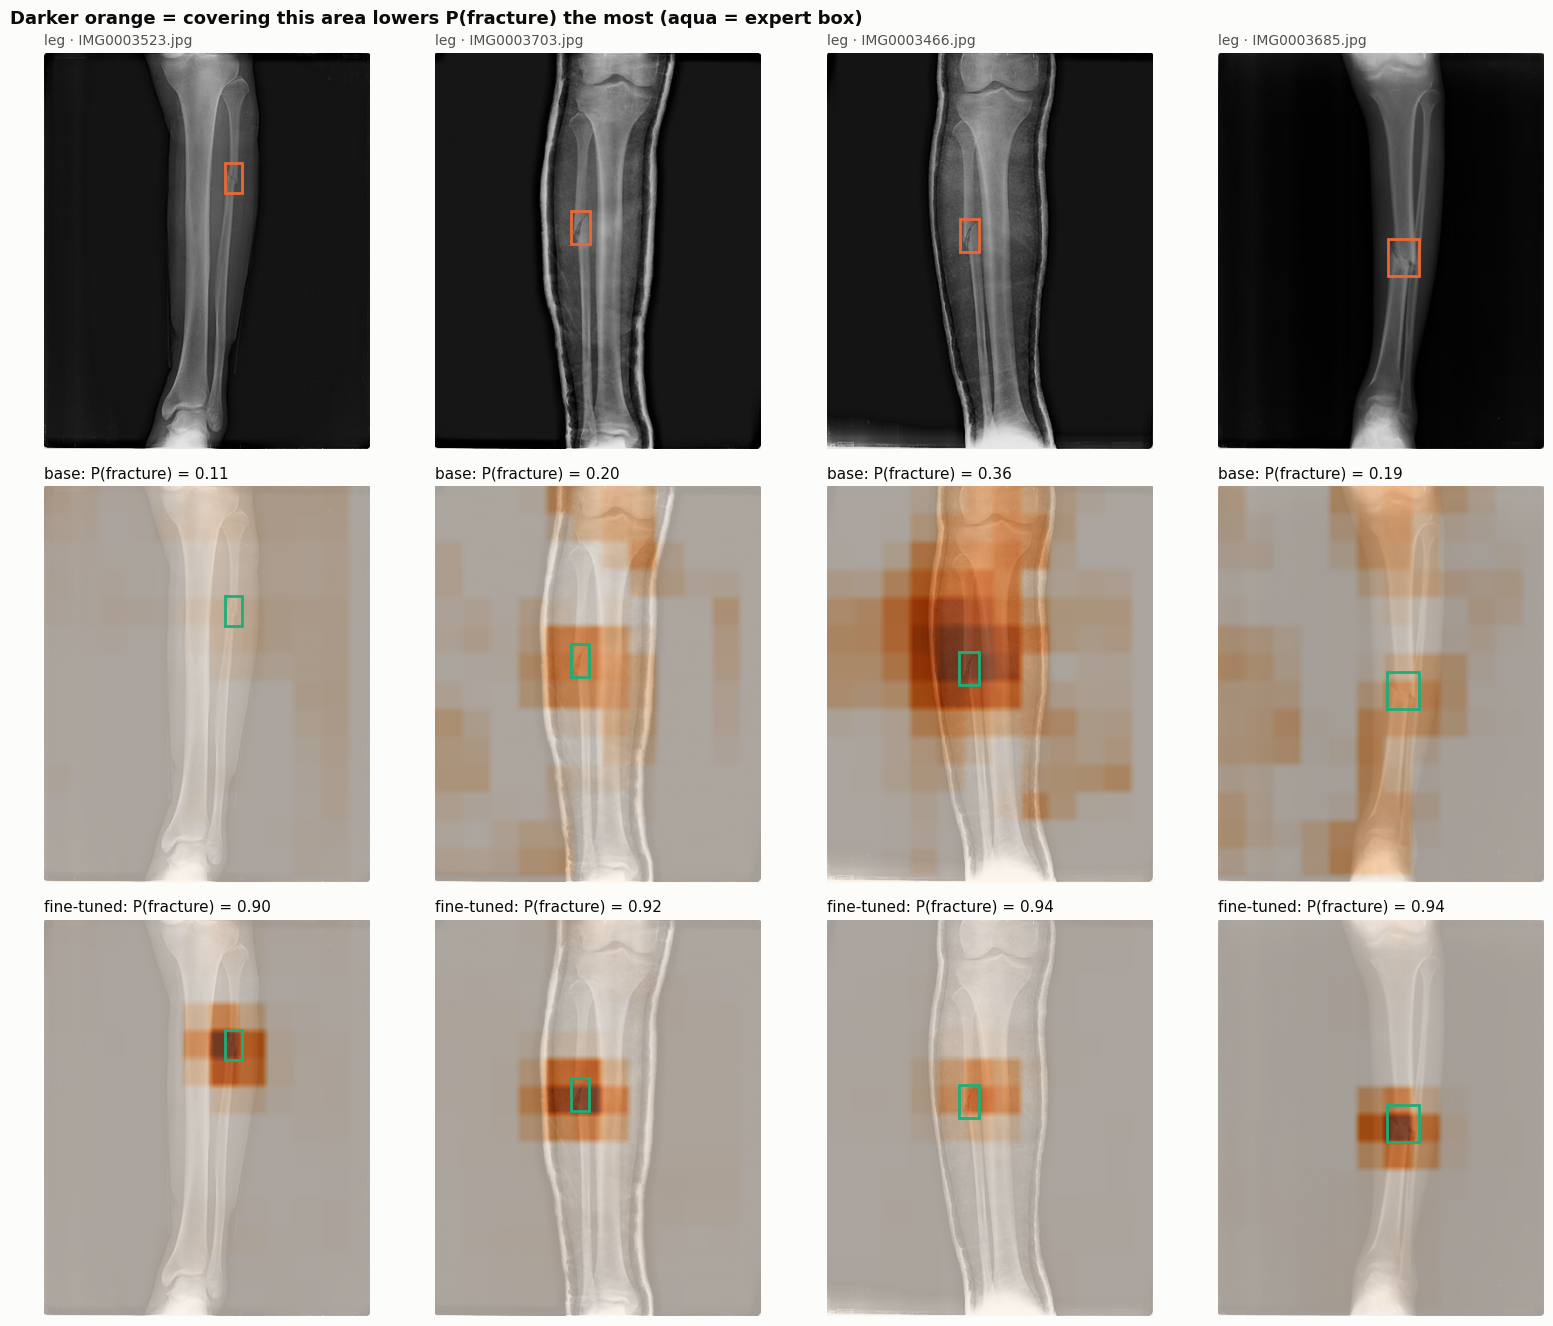

In [26]:
#@title Occlusion maps: base vs fine-tuned
occ = json.loads((R / "visuals" / "occlusion_index.json").read_text())
occ = sorted(occ, key=lambda d: d["p_finetuned"])[:4]  # at P = 0.99 one patch cannot move it (saturation)
fig, axes = plt.subplots(3, 4, figsize=(16, 13.5))
for c, item in enumerate(occ):
    iid = item["image_id"]
    maps = np.load(R / "visuals" / f"occlusion_{iid.removesuffix('.jpg')}.npz")
    im = image(iid)
    w, h = im.size
    vmax = max(np.percentile(np.clip(maps[k].astype(float), 0, None), 99.5) for k in ("base", "finetuned")) or 1e-3
    show_xray(axes[0, c], iid, title=f"{item['body_part']} · {iid}")
    for r, (key, name, p) in enumerate([("base", "base", item["p_base"]), ("finetuned", "fine-tuned", item["p_finetuned"])], 1):
        ax = axes[r, c]
        ax.imshow(im.convert("L"), cmap="gray")
        ax.imshow(np.clip(maps[key].astype(float), 0, None), cmap="Oranges", alpha=0.65, vmin=0, vmax=vmax,
                  extent=(0, w, h, 0), interpolation="bilinear")
        for x, y, bw, bh in item["boxes"]:
            ax.add_patch(Rectangle((x * w, y * h), bw * w, bh * h, fill=False, ec=AQUA, lw=2))
        ax.set_axis_off()
        ax.set_title(f"{name}: P(fracture) = {p:.2f}", fontsize=11, fontweight="normal")
fig.suptitle("Darker orange = covering this area lowers P(fracture) the most (aqua = expert box)",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

In these four cases the fine-tuned model's evidence sits right on the fracture, while the base model's is spread along the whole bone. Fine-tuning taught it *where* to look, not just what to write.

In general, compare the hot spots with the expert boxes. Where the fine-tuned model's evidence overlaps the fracture, it is "right for the right reason". Where it lights up elsewhere (cast edges, hardware, image borders), it may be using a **shortcut**. Occlusion maps are coarse and only show what changes the score, but they are a quick sanity check that needs no access to the model's internals.

---
## Part 10 · Clinical read

Eight fine-tuned reports from the test set: correct calls, missed fractures and false alarms. Would you sign them? What would make you trust (or distrust) this model in your department?

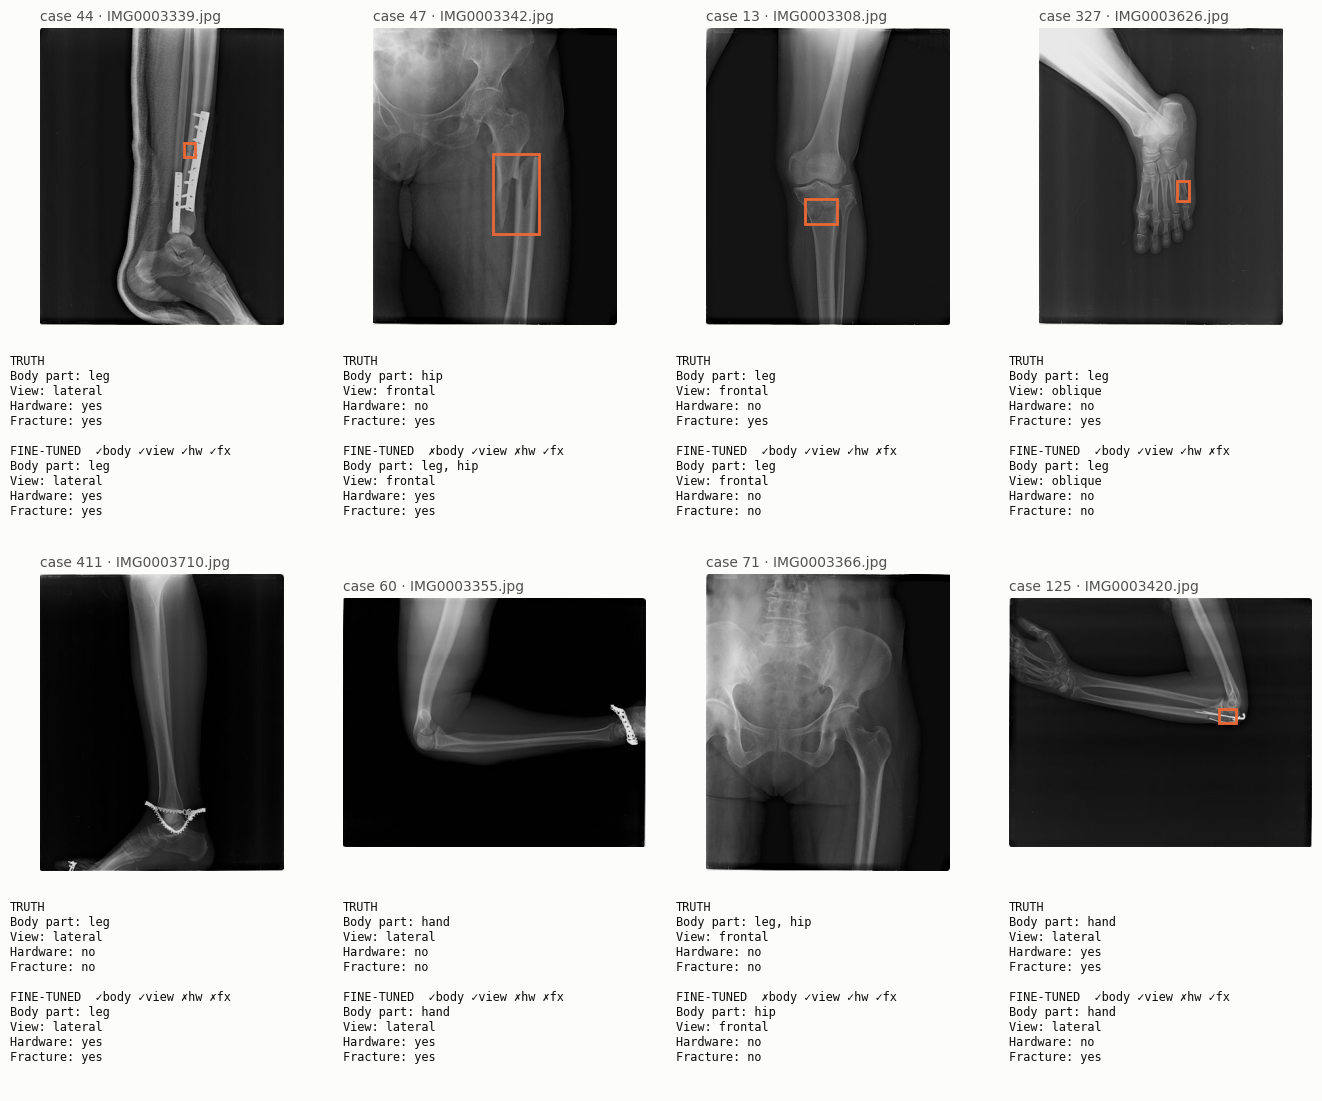

In [27]:
#@title Would you sign these reports?
q = preds("main")
tp = q[(q.true_fracture == 1) & (q.pred_fracture == 1)].sort_values("p_fracture", ascending=False)
fn = q[(q.true_fracture == 1) & (q.pred_fracture == 0)].sort_values("p_fracture")
fp = q[(q.true_fracture == 0) & (q.pred_fracture == 1)].sort_values("p_fracture", ascending=False)
wrong_part = q[(q.pred_body_part != q.true_body_part) & (q.true_fracture == 0)]
hardware = q[q.true_hardware == 1]
READ = list(dict.fromkeys([*tp.index[1:3], *fn.index[:2], *fp.index[:2], wrong_part.index[0], hardware.index[-1]]))
cards(READ, runs=("main",))

**Look closely** at the false alarms: some patients are wearing jewelry (an anklet, a bracelet). The model calls the jewelry *hardware*, and then also calls a fracture: a shortcut, because hardware and fractures often appear together in the training images.

**Questions for the room**
- Which errors are dangerous and which are harmless? (A missed fracture vs. a wrong view.)
- Would a probability or a heat map change how you use the output?
- This model was trained on one public dataset from three hospitals. What would you need to check before using it on *your* scanners and *your* patients?
- Go through the **"Would I trust this?" checklist** from *Before the code*. How many questions can you answer yes?

**Automation bias.** In a reader study, very experienced radiologists were right 82% of the time when a (simulated) AI suggested the correct BI-RADS category, but only 45.5% when it suggested a wrong one ([Dratsch et al., *Radiology* 2023](https://doi.org/10.1148/radiol.222176)). A confident wrong answer pulls readers with it. Real clinical use would need local validation, a reader study and a regulatory path.

---
## Take-home messages

1. **A VLM = vision encoder + projector + language model.** Fine-tuning can target any part; LoRA trains less than 1% of the weights and fits on a free GPU.
2. **Format is learned in minutes, content needs data.** 64 images teach the report format; fracture detection kept improving up to all 3,258 images.
3. **Data quality decides the outcome.** Check splits by patient, look for duplicates, and know your class balance.
4. **Accuracy can lie.** Report sensitivity, specificity and AUC, and pick the operating point for the clinical use.
5. **Probe for failure.** Hallucination on non-X-ray inputs, shortcuts, number-format (fp16) problems and forgetting do not show up in a single accuracy number.

### Keep going
- **Your own data:** get IRB and data-governance approval, de-identify, train only on compute your institution approves (never in a personal Colab), and split by patient.
- **Next today:** Lab 08 at 9:30 AM, *An Introduction to Sourcing and Preprocessing Medical Imaging Data for Vision-Language Models*, shows how to turn raw clinical data into de-identified image-report pairs for VLM training.
- **The training scripts** for this lab (data preparation, LoRA training, evaluation) are in the [`training/`](https://github.com/RSNA/AI-Deep-Learning-Lab-2026/tree/main/07-Fine-Tuning-Vision-Language-Models/training) folder.
- **Libraries:** [Hugging Face TRL](https://huggingface.co/docs/trl) (training), [PEFT](https://huggingface.co/docs/peft) (LoRA), [Transformers](https://huggingface.co/docs/transformers).
- **After the workshop:** the dataset and adapter stay public. If downloads are slow, create a free Hugging Face account and add your own token in Colab under **Secrets** (key icon) as `HF_TOKEN`.

### Credits and licenses
- **Data:** Abedeen I, Rahman MA, Prottyasha FZ, et al. *FracAtlas: A Dataset for Fracture Classification, Localization and Segmentation of Musculoskeletal Radiographs.* Sci Data 10, 521 (2023). [doi:10.6084/m9.figshare.22363012](https://doi.org/10.6084/m9.figshare.22363012), CC BY 4.0. We resized the images and reformatted the labels.
- **Model:** [Qwen3-VL-2B-Instruct](https://huggingface.co/Qwen/Qwen3-VL-2B-Instruct), Qwen team, Apache-2.0.
- Hosted on Hugging Face: [dataset](https://huggingface.co/datasets/magnooj/fracatlas-vlm-512) · [adapter and results](https://huggingface.co/magnooj/qwen3-vl-2b-fracatlas-lora).